# Proyecto Centinela - Fase 2: Centinela de la Papa multimodal
### Redes Neuronales - Deep Learning (EA-N-F-004) - Maestría en Ciencia de Datos, USTA
Integrantes: Juan Guillermo Montaño Junca y Jair Andrés Valderrama Cano - versión v2 (ejecutada en Colab, GPU T4, 7 de noviembre de 2026)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/N3UR0SlS/Centinela-Papa/blob/main/notebooks/02_centinela_fase2_papa.ipynb)

Mismo cliente y mismo problema de la Fase 1 (alerta temprana de tizón en papa, región de Mbeya, Tanzania). La Fase 2 da dos pasos:
1. La imagen deja de aplanarse en 10 rasgos de color y entra cruda a una **CNN con transfer learning** (rama A).
2. Entra por primera vez la segunda modalidad: **25 años de clima horario de NASA POWER** procesados por **RNN / LSTM / GRU** (rama B), y las dos ramas se **fusionan** con una clave de alineación real por foto (rama C).

| | Fase 1 (`01_centinela_fase1_papa.ipynb`) | Fase 2 (este cuaderno) |
|---|---|---|
| Imagen | 10 rasgos tabulares por hoja (aplanada) | foto cruda 224 px, ResNet50 y MobileNetV3 |
| Clima | solo en la propuesta (Anexo A) | serie diaria 2001-2025, 2 celdas, LSTM/GRU |
| Modelo | MLP 128-64 | CNN + red recurrente + fusión tardía |
| Muestra | 58.707 hojas (rasgos) | 6.695 fotos (1.000 por clase + días mixtos) |
| Pregunta | ¿la hoja está enferma? | ¿qué tizón tiene la hoja?, ¿viene clima de riesgo?, ¿suma el clima a la foto? |

**Ejecución:** Colab con GPU (Entorno de ejecución, Cambiar tipo de entorno, T4). Todo se baja del repositorio en segundos, nada va a Drive. Con GPU el cuaderno completo tarda unos 25 minutos.

Estructura: 0 entorno - 1 datos y clave de alineación - 2 rama A visión - 3 rama B secuencia - 4 rama C fusión y ablación - 5 autoevaluación - anexos A auditoría, B propuesta v2, C bitácora, D informe.

## 0. Preparación del entorno
Semillas en las tres librerías, GPU si la hay y la misma paleta de la Fase 1 (sana azul, temprano naranja, tardío verde). `SMOKE` es solo para probar el cuaderno rápido en CPU (pocas fotos, pocas épocas, sin pesos preentrenados); en la entrega va en `False`.

In [1]:
import os, io, json, time, zipfile, random, urllib.request, copy
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from PIL import Image, ImageFile
from collections import Counter
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision.transforms import v2 as T
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score, average_precision_score,
                             f1_score, recall_score, precision_score, mean_absolute_error, mean_squared_error)
ImageFile.LOAD_TRUNCATED_IMAGES = True

SMOKE = os.environ.get("CENTINELA_SMOKE") == "1"     # solo para pruebas rapidas en CPU
SEMILLA = 42
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True

CLASES = ["sana", "temprano", "tardio"]
NOMBRE = {"sana": "Sana", "temprano": "Tizón temprano", "tardio": "Tizón tardío"}
COLOR = {"sana": "#2a78d6", "temprano": "#eb6834", "tardio": "#1baf7a"}
COL_MOD = {"RNN": "#9a9a9a", "LSTM": "#6b4fbb", "GRU": "#d6336c",
           "solo-imagen": "#2a78d6", "solo-serie": "#e0a100", "fusion": "#1baf7a", "solo-fecha": "#9a9a9a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.formatter.use_locale": False, "font.size": 10})
def coma(x, d=3): return f"{x:.{d}f}".replace(".", ",")
os.makedirs("figuras", exist_ok=True); os.makedirs("pesos", exist_ok=True)
RESULTADOS = {}            # todo lo que se reporta en el informe sale de aqui
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE, "| SMOKE:", SMOKE)
if DEVICE == "cpu" and not SMOKE:
    print("AVISO: sin GPU la rama A tarda mucho. En Colab: Entorno de ejecucion > Cambiar tipo > T4 GPU.")

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda | SMOKE: False


## 1. Los datos multimodales y su clave de alineación

Resumen de la Propuesta de Datos v2 (completa en el Anexo B):

| Elemento | Decisión |
|---|---|
| Cliente | Extensionistas y cooperativas de papa de la región de Mbeya (el mismo de la Fase 1) |
| Modalidad 1: imagen | Irish Potato Imagery Dataset (Laizer et al., Zenodo, CC BY 4.0): muestra de 6.695 fotos de campo, 3 clases, reducidas a 256 px y **sin EXIF** con `notebooks/preparar_imagenes_fase2.py` |
| Modalidad 2: serie | NASA POWER horario 2001-2025 (MERRA-2, reanálisis satelital, no estación), resumido por día con `notebooks/descargar_clima_fase2.py` |
| Clave de alineación | **(fecha de la toma, celda NASA POWER)**. La fecha sale del EXIF de cada foto (100 % la traen); la celda sale del GPS cuando existe y, si no, se asigna la celda dominante de Mbeya |
| Etiquetas | Imagen: sana / temprano / tardío (carpeta del autor). Serie: periodo de Hutton (Tmin >= 10 °C y >= 6 h con HR >= 90 %, dos días seguidos) |

**Por qué esta clave es legítima pero peligrosa.** Cada foto tiene su fecha real, así que el emparejamiento foto-clima es un co-registro genuino por muestra, no un pareo artificial. El problema es otro, y la Fase 1 ya lo midió: en este dataset la clase depende del día de la campaña (la fecha sola daba AUC 0,998). Como el clima es igual para todas las fotos de un mismo día, **el clima puede funcionar como un "código de fecha"** y parecer predictivo sin serlo. La rama C se diseña para medir eso y no dejarse engañar.

In [2]:
# Celda 1 - Descarga de las dos modalidades desde el repositorio (sin Drive, sin Zenodo)
REPO_RAW = "https://raw.githubusercontent.com/N3UR0SlS/Centinela-Papa/main/datos_derivados/"
ZIP_URL  = "https://github.com/N3UR0SlS/Centinela-Papa/releases/download/datos-fase2/imagenes_fase2.zip"
ARCHIVOS = {"manifiesto_fase2.csv": REPO_RAW + "manifiesto_fase2.csv",
            "clima_mbeya_diario.csv": REPO_RAW + "clima_mbeya_diario.csv",
            "imagenes_fase2.zip": ZIP_URL}
for nombre, url in ARCHIVOS.items():
    if os.path.exists(nombre):
        print("Ya estaba:", nombre); continue
    t0 = time.time(); urllib.request.urlretrieve(url, nombre)
    print(f"Bajado: {nombre} ({os.path.getsize(nombre)/1e6:.1f} MB en {time.time()-t0:.0f} s)")

Bajado: manifiesto_fase2.csv (0.3 MB en 0 s)
Bajado: clima_mbeya_diario.csv (1.3 MB en 0 s)
Bajado: imagenes_fase2.zip (142.4 MB en 2 s)


In [3]:
# Celda 2 - Manifiesto e imagenes en memoria (sin except silencioso: cada error se cuenta)
man = pd.read_csv("manifiesto_fase2.csv")
if SMOKE:
    mix = man[man["fecha"].isin(["2023-01-23", "2023-01-30"])].groupby(["fecha", "enferma"]).sample(n=15, random_state=SEMILLA)
    man = pd.concat([man.groupby("clase").sample(n=70, random_state=SEMILLA), mix]).drop_duplicates("archivo")
man = man.reset_index(drop=True)
LADO = 256
errores, imgs, ok = Counter(), [], []
with zipfile.ZipFile("imagenes_fase2.zip") as z:
    nombres_zip = set(z.namelist())
    for a in man["archivo"]:
        try:
            im = Image.open(io.BytesIO(z.read(a))).convert("RGB")
            if im.size != (LADO, LADO): im = im.resize((LADO, LADO))
            imgs.append(np.asarray(im, dtype=np.uint8)); ok.append(True)
        except Exception as e:
            errores[type(e).__name__] += 1; ok.append(False)
man = man[np.array(ok)].reset_index(drop=True)
X_u8 = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).contiguous()     # (N,3,256,256) uint8
del imgs
man["y3"] = man["clase"].map({c: i for i, c in enumerate(CLASES)})
man["fecha"] = pd.to_datetime(man["fecha"])
print(f"Fotos cargadas: {len(man)} | errores: {dict(errores) or 'ninguno'} | tensor {tuple(X_u8.shape)} "
      f"({X_u8.numel()/1e9:.2f} GB)")
print(man["clase"].value_counts().reindex(CLASES).to_string())
RESULTADOS["n_fotos"] = int(len(man)); RESULTADOS["errores_carga"] = dict(errores)

Fotos cargadas: 6695 | errores: ninguno | tensor (6695, 3, 256, 256) (1.32 GB)
clase
sana        3018
temprano    1676
tardio      2001


In [4]:
# Celda 3 - Clima diario y etiqueta de Hutton
clima = pd.read_csv("clima_mbeya_diario.csv", parse_dates=["fecha"])
clima["celda"] = clima["celda_lat"].map(lambda v: f"{v:.3f}") + "/" + clima["celda_lon"].map(lambda v: f"{v:.3f}")
VARS = ["t_media", "t_min", "t_max", "hr_media", "hr_max", "horas_hr90", "lluvia_mm", "viento_ms"]
print("Dias por celda:", clima.groupby("celda").size().to_dict())
print("Faltantes por variable:", clima[VARS].isna().sum().to_dict())
print("Dias con menos de 24 horas validas:", int((clima["horas_validas"] < 24).sum()))
# Faltantes: interpolacion lineal dentro de cada celda (son pocos; se reportan arriba)
clima = clima.sort_values(["celda", "fecha"]).reset_index(drop=True)
clima[VARS] = clima.groupby("celda")[VARS].transform(lambda s: s.interpolate(limit_direction="both"))

# Hutton (Met Office, 2017): dos dias seguidos con Tmin >= 10 C y >= 6 h con HR >= 90 %
clima["dia_hutton"] = ((clima["t_min"] >= 10) & (clima["horas_hr90"] >= 6)).astype(int)
clima["periodo_hutton"] = (clima["dia_hutton"] & clima.groupby("celda")["dia_hutton"].shift(1).fillna(0).astype(int)).astype(int)
CELDA_DOM = clima["celda"].value_counts().index[0] if "-9.000/33.750" not in set(clima["celda"]) else "-9.000/33.750"
print("Celda dominante (Mbeya):", CELDA_DOM)
print(f"Dias Hutton: {clima['dia_hutton'].mean():.1%} | periodos Hutton: {clima['periodo_hutton'].mean():.1%} (celda dominante y vecina)")

Dias por celda: {'-9.000/33.125': 9131, '-9.000/33.750': 9131}
Faltantes por variable: {'t_media': 0, 't_min': 0, 't_max': 0, 'hr_media': 0, 'hr_max': 0, 'horas_hr90': 0, 'lluvia_mm': 0, 'viento_ms': 0}
Dias con menos de 24 horas validas: 0
Celda dominante (Mbeya): -9.000/33.750
Dias Hutton: 60.6% | periodos Hutton: 55.4% (celda dominante y vecina)


In [5]:
# Celda 4 - Clave de alineacion foto -> (fecha, celda): co-registro por muestra
def celda_foto(r):
    if r["tiene_gps"] == 1 and pd.notna(r["celda_lat"]):
        return f"{r['celda_lat']:.3f}/{r['celda_lon']:.3f}", "GPS de la foto"
    return CELDA_DOM, "celda dominante (sin GPS util)"
tmp = man.apply(celda_foto, axis=1, result_type="expand"); man["celda"], man["origen_celda"] = tmp[0], tmp[1]
llaves = set(zip(clima["celda"], clima["fecha"]))
man["clima_ok"] = [(c, f) in llaves for c, f in zip(man["celda"], man["fecha"])]
print(man.groupby(["origen_celda", "celda"]).size().rename("fotos").to_string())
print(f"\nFotos con clima encontrado para su (celda, fecha): {man['clima_ok'].mean():.1%}")
print(f"Dias distintos de toma: {man['fecha'].nunique()} | de {man['fecha'].min():%d-%m-%Y} a {man['fecha'].max():%d-%m-%Y}")
# Diferencia entre las dos celdas: si es minima, asignar la dominante a las fotos sin GPS cuesta poco
piv = clima.pivot_table(index="fecha", columns="celda", values="t_min")
if piv.shape[1] == 2:
    d = (piv.iloc[:, 0] - piv.iloc[:, 1]).abs()
    print(f"Diferencia media de Tmin entre las dos celdas: {d.mean():.2f} C (p95 {d.quantile(.95):.2f} C)")
RESULTADOS["alineacion"] = {"pct_clima_ok": float(man["clima_ok"].mean()),
                            "fotos_por_origen": man["origen_celda"].value_counts().to_dict(),
                            "dias_toma": int(man["fecha"].nunique())}

origen_celda                    celda        
GPS de la foto                  -9.000/33.125       7
                                -9.000/33.750     195
celda dominante (sin GPS util)  -9.000/33.750    6493

Fotos con clima encontrado para su (celda, fecha): 100.0%
Dias distintos de toma: 30 | de 07-01-2023 a 03-03-2023
Diferencia media de Tmin entre las dos celdas: 2.77 C (p95 4.95 C)


## 2. Rama A - Visión: CNN con transfer learning

**Tarea:** clasificar cada hoja en sana, tizón temprano o tizón tardío (3 clases). Con 6.695 fotos no tiene sentido entrenar una CNN desde cero; se parte de redes preentrenadas en ImageNet.

**Por qué una CNN y no el MLP de la Fase 1.** El MLP veía 10 números por hoja (medias de color, fracción parduzca, textura). Una convolución recorre la imagen con el mismo filtro y detecta patrones locales (anillos concéntricos del tizón temprano, manchas acuosas del tardío) sin importar dónde estén en la hoja. Comparte pesos, así que tiene muchos menos parámetros que un MLP conectado a cada píxel, y conserva la estructura espacial que la tabla perdía.

### 2.1 Análisis exploratorio de las imágenes

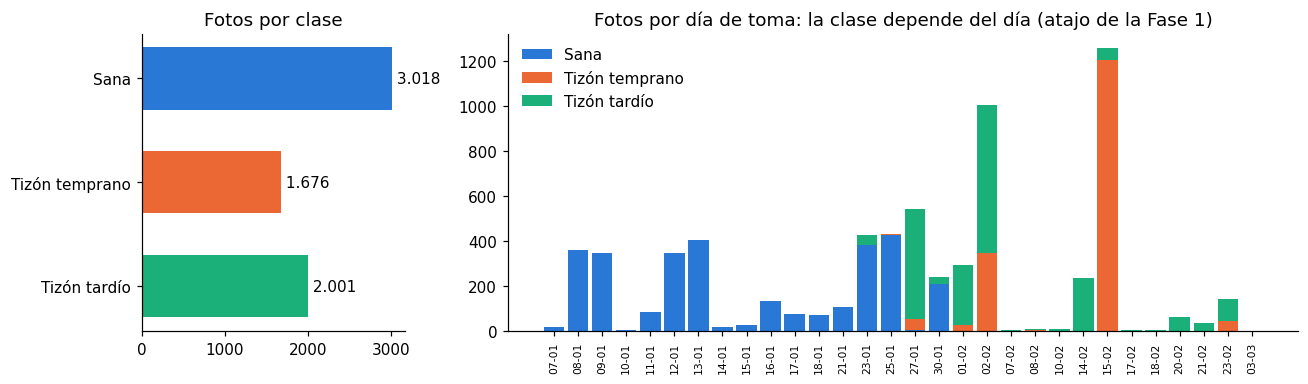

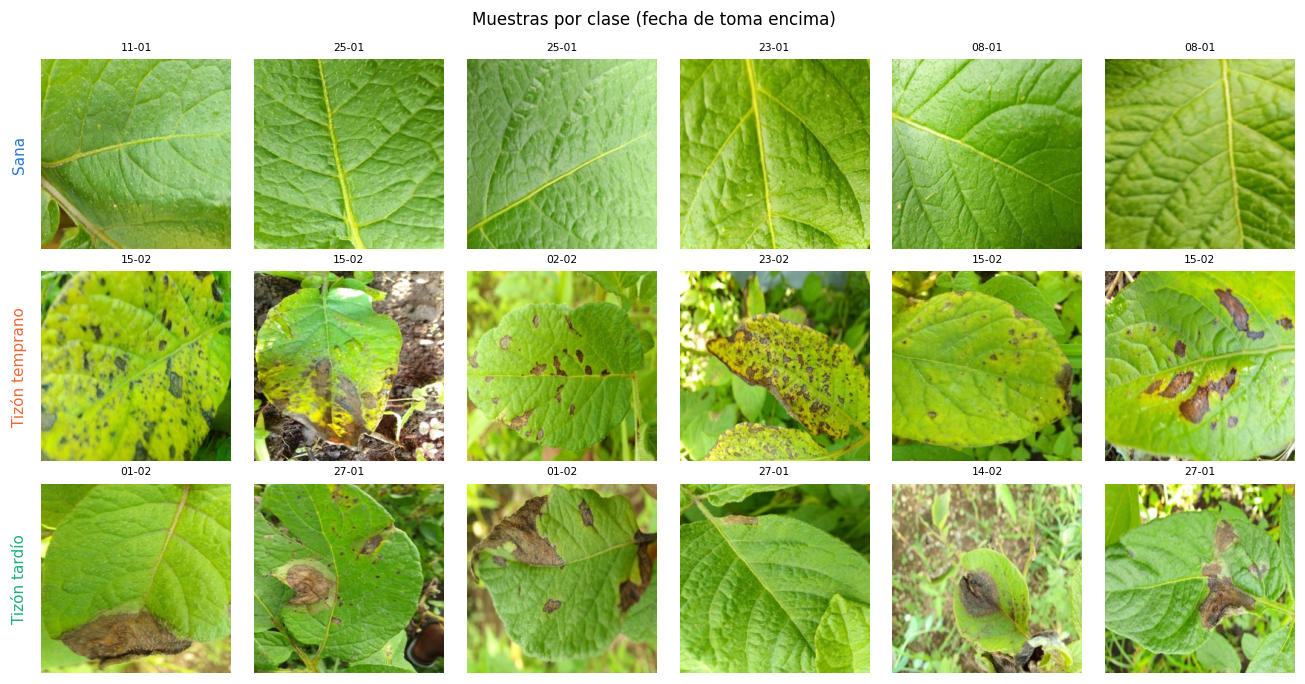

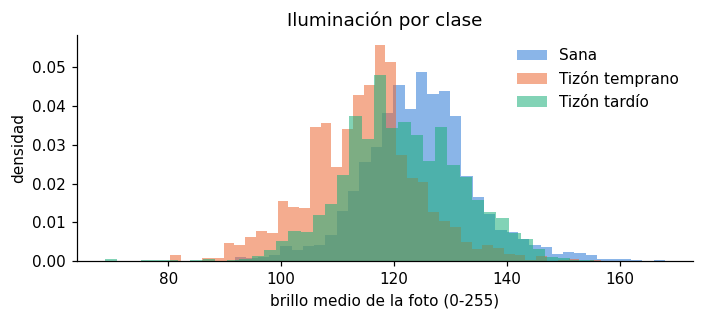

Sana            brillo medio  124.6 | desv   9.9
Tizón temprano  brillo medio  114.6 | desv  10.0
Tizón tardío    brillo medio  121.5 | desv  10.6


In [6]:
# Celda 5 - EDA: balance, fotos por dia y clase, muestras e iluminacion
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 3]})
cnt = man["clase"].value_counts().reindex(CLASES)
ax[0].barh([NOMBRE[c] for c in CLASES], cnt.values, color=[COLOR[c] for c in CLASES], height=0.6)
for i, v in enumerate(cnt.values): ax[0].text(v, i, f" {v:,}".replace(",", "."), va="center")
ax[0].set_title("Fotos por clase"); ax[0].invert_yaxis()
tab = man.groupby([man["fecha"].dt.date, "clase"]).size().unstack(fill_value=0).reindex(columns=CLASES, fill_value=0)
abajo = np.zeros(len(tab))
for c in CLASES:
    ax[1].bar(range(len(tab)), tab[c].values, bottom=abajo, color=COLOR[c], label=NOMBRE[c], width=0.85); abajo += tab[c].values
ax[1].set_xticks(range(len(tab))); ax[1].set_xticklabels([f"{d:%d-%m}" for d in tab.index], rotation=90, fontsize=7)
ax[1].set_title("Fotos por día de toma: la clase depende del día (atajo de la Fase 1)"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("figuras/f2_eda_clases_dias.png", dpi=200, bbox_inches="tight"); plt.show()

# Muestras por clase
rng = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(3, 6, figsize=(12, 6.3))
for i, c in enumerate(CLASES):
    idx = rng.choice(np.where(man["clase"] == c)[0], 6, replace=False)
    for j, k in enumerate(idx):
        axes[i, j].imshow(X_u8[k].permute(1, 2, 0).numpy()); axes[i, j].axis("off")
        axes[i, j].set_title(f"{man['fecha'][k]:%d-%m}", fontsize=7)
    axes[i, 0].text(-20, 128, NOMBRE[c], rotation=90, va="center", ha="right", fontsize=10, color=COLOR[c])
plt.suptitle("Muestras por clase (fecha de toma encima)", fontsize=11); plt.tight_layout()
plt.savefig("figuras/f2_muestras.png", dpi=200, bbox_inches="tight"); plt.show()

# Iluminacion: brillo medio por foto y clase (variabilidad de luz de campo)
brillo = X_u8.float().mean((1, 2, 3)).numpy()
fig, ax = plt.subplots(figsize=(6.5, 3))
for c in CLASES:
    ax.hist(brillo[man["clase"] == c], bins=40, alpha=0.55, color=COLOR[c], label=NOMBRE[c], density=True)
ax.set_xlabel("brillo medio de la foto (0-255)"); ax.set_ylabel("densidad"); ax.legend(frameon=False)
ax.set_title("Iluminación por clase"); plt.tight_layout(); plt.show()
for c in CLASES:
    b = brillo[man["clase"] == c]; print(f"{NOMBRE[c]:15} brillo medio {b.mean():6.1f} | desv {b.std():5.1f}")

**Lo que decide este EDA** (las cifras exactas salen de la celda anterior):
- Las clases quedan razonablemente balanceadas (la muestra se armó con un tope por clase), pero igual se usan pesos por clase en la pérdida y se reportan precisión, recall y F1 **por clase**, no solo exactitud.
- La gráfica por día repite el hallazgo de la Fase 1: casi todos los días tienen una sola clase. Por eso, además de la partición 70/15/15, se mide la red **dentro de los días mixtos** (23 y 30 de enero), donde la fecha no ayuda.
- Las fotos son de campo: fondo de suelo y otras hojas, sombras, distintas horas del día. Eso justifica el aumento de datos con brillo y contraste además de giros y recortes.

### 2.2 Partición y aumento de datos
Partición **70/15/15 estratificada por clase**, con semilla fija. Es la que pide la actividad y permite comparar con la Fase 1. No se parte por día porque hay días con una sola clase: un día completo en prueba dejaría clases ausentes. El riesgo de que la red aprenda el día en vez de la lesión se mide aparte (2.6).

Aumento de datos solo en entrenamiento: recorte aleatorio (60 a 100 % del área), giros horizontal y vertical, rotación de hasta 25° y variación de brillo, contraste y saturación. Una hoja enferma sigue enferma si se gira o si la foto se tomó con más sol; un cambio de tono fuerte (hue) no se usa porque el color pardo **es** el síntoma.

In [7]:
# Celda 6 - Particion 70/15/15 y datasets con aumento de datos
idx_all = np.arange(len(man))
idx_tr, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=man["y3"], random_state=SEMILLA)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=man["y3"].values[idx_tmp], random_state=SEMILLA)
man["split"] = "train"; man.loc[idx_va, "split"] = "val"; man.loc[idx_te, "split"] = "test"
print(pd.crosstab(man["split"], man["clase"]).reindex(columns=CLASES).to_string())

TAM = 128 if SMOKE else 224
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = T.Compose([T.RandomResizedCrop(TAM, scale=(0.6, 1.0), antialias=True), T.RandomHorizontalFlip(),
                      T.RandomVerticalFlip(), T.RandomRotation(25),
                      T.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15),
                      T.ToDtype(torch.float32, scale=True), T.Normalize(MEDIA, DESV)])
tf_eval = T.Compose([T.Resize(TAM, antialias=True), T.ToDtype(torch.float32, scale=True), T.Normalize(MEDIA, DESV)])

class Hojas(torch.utils.data.Dataset):
    def __init__(self, idx, tf): self.idx, self.tf = np.asarray(idx), tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        k = self.idx[i]; return self.tf(X_u8[k]), int(man["y3"].values[k])

def cargador(idx, tf, bs=64, barajar=False):
    return torch.utils.data.DataLoader(Hojas(idx, tf), batch_size=bs, shuffle=barajar,
                                       num_workers=2, pin_memory=(DEVICE == "cuda"))
y_tr = man["y3"].values[idx_tr]
peso_clase = torch.tensor(len(y_tr) / (3 * np.bincount(y_tr, minlength=3)), dtype=torch.float32)
print("Pesos por clase en la perdida:", dict(zip(CLASES, peso_clase.numpy().round(2))))

clase  sana  temprano  tardio
split                        
test    453       252     300
train  2112      1173    1401
val     453       251     300
Pesos por clase en la perdida: {'sana': np.float32(0.74), 'temprano': np.float32(1.33), 'tardio': np.float32(1.11)}


### 2.3 Dos arquitecturas preentrenadas: ResNet50 frente a MobileNetV3-Large
- **ResNet50** (He et al., 2016): 50 capas con conexiones residuales, 25 M de parámetros. Es el estándar para transfer learning y la referencia de la actividad.
- **MobileNetV3-Large** (Howard et al., 2019): convoluciones separables y bloques de compresión, unos 5 M de parámetros. Se elige como segunda porque la Fase 3 pide desplegar la rama visual **offline en el borde** (un celular de un extensionista en Mbeya), y ahí el tamaño y la latencia pesan tanto como la exactitud.

Similitud con ImageNet: media. ImageNet tiene plantas y hojas, pero no lesiones de tizón; los filtros de bordes, texturas y color de las primeras capas sirven tal cual, y los de las últimas capas son más específicos de los objetos de ImageNet. Con ~4.700 fotos de entrenamiento, eso sugiere probar **las dos estrategias**: *feature extraction* (congelar todo y entrenar solo la cabeza) y *fine-tuning* (descongelar los últimos bloques con tasa baja). Se deciden con evidencia, no por regla.

In [8]:
# Celda 7 - Ficha tecnica de las dos arquitecturas: parametros, profundidad y latencia
def crear_backbone(nombre, preentrenado=not SMOKE):
    if nombre == "ResNet50":
        m = torchvision.models.resnet50(weights="IMAGENET1K_V2" if preentrenado else None)
        dim = m.fc.in_features; m.fc = nn.Identity()
    else:
        m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V2" if preentrenado else None)
        dim = m.classifier[0].in_features; m.classifier = nn.Identity()
    return m, dim

def profundidad(m):   # capas con pesos (conv + lineales)
    return sum(isinstance(x, (nn.Conv2d, nn.Linear)) for x in m.modules())

@torch.no_grad()
def latencia_ms(m, reps=30, bs=1):
    m.eval().to(DEVICE); x = torch.randn(bs, 3, TAM, TAM, device=DEVICE)
    for _ in range(5): m(x)
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps): m(x)
    if DEVICE == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps * 1000

ARQS = ["ResNet50", "MobileNetV3"]
ficha = []
for a in ARQS:
    m, dim = crear_backbone(a)
    ficha.append({"arquitectura": a, "parametros_M": sum(p.numel() for p in m.parameters()) / 1e6,
                  "capas_con_pesos": profundidad(m), "dim_embedding": dim,
                  "latencia_ms_1img": latencia_ms(m), "tamano_MB": sum(p.numel() for p in m.parameters()) * 4 / 1e6})
    del m
ficha = pd.DataFrame(ficha).set_index("arquitectura")
print(f"Latencia medida en {DEVICE}, 1 imagen de {TAM}x{TAM}:")
print(ficha.round(2).to_string())
RESULTADOS["ficha_arquitecturas"] = ficha.round(3).reset_index().to_dict("records")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 158MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 78.9MB/s]


Latencia medida en cuda, 1 imagen de 224x224:
              parametros_M  capas_con_pesos  dim_embedding  latencia_ms_1img  tamano_MB
arquitectura                                                                           
ResNet50             23.51               53           2048              6.18      94.03
MobileNetV3           2.97               62            960              6.44      11.89


In [9]:
# Celda 8 - Feature extraction: backbone congelado, se entrena solo la cabeza
@torch.no_grad()
def extraer(backbone, idx, bs=128):
    backbone.eval().to(DEVICE); out = []
    for xb, _ in cargador(idx, tf_eval, bs):
        out.append(backbone(xb.to(DEVICE, non_blocking=True)).float().cpu())
    return torch.cat(out)

class Cabeza(nn.Module):
    def __init__(self, d, k=3, oculta=256, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, oculta), nn.ReLU(), nn.Dropout(p), nn.Linear(oculta, k))
    def forward(self, x): return self.net(x)

def entrenar_cabeza(Ftr, ytr, Fva, yva, epocas=150, paciencia=15, lr=1e-3, k=3):
    fijar_semilla(); cab = Cabeza(Ftr.shape[1], k).to(DEVICE)
    opt = torch.optim.AdamW(cab.parameters(), lr=lr, weight_decay=1e-3)
    crit = nn.CrossEntropyLoss(weight=peso_clase.to(DEVICE) if k == 3 else None)
    Ftr, Fva = Ftr.to(DEVICE), Fva.to(DEVICE)
    ytr_t, yva_t = torch.as_tensor(ytr, device=DEVICE), torch.as_tensor(yva, device=DEVICE)
    mejor, estado, sin_mejora, hist = 1e9, None, 0, []
    for ep in range(epocas):
        cab.train(); perm = torch.randperm(len(Ftr), device=DEVICE)
        for j in range(0, len(Ftr), 128):
            b = perm[j:j + 128]; opt.zero_grad(); crit(cab(Ftr[b]), ytr_t[b]).backward(); opt.step()
        cab.eval()
        with torch.no_grad(): lv = crit(cab(Fva), yva_t).item()
        hist.append(lv)
        if lv < mejor - 1e-4: mejor, estado, sin_mejora = lv, copy.deepcopy(cab.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: break
    cab.load_state_dict(estado); return cab.eval(), hist

@torch.no_grad()
def prob_cabeza(cab, Fx): return torch.softmax(cab(Fx.to(DEVICE)), 1).cpu().numpy()

def metricas3(y, P):
    pred = P.argmax(1); enf = P[:, 1] + P[:, 2]
    return {"exactitud": float((pred == y).mean()), "f1_macro": float(f1_score(y, pred, average="macro")),
            "auc_enferma": float(roc_auc_score((y > 0).astype(int), enf)) if len(set(y > 0)) == 2 else float("nan")}

FEATS, CABEZAS_FE, RES_A = {}, {}, {}
y_va, y_te = man["y3"].values[idx_va], man["y3"].values[idx_te]
for a in ARQS:
    t0 = time.time(); bb, dim = crear_backbone(a)
    for p in bb.parameters(): p.requires_grad = False
    FEATS[a] = {"bb": bb, "dim": dim, "todas": extraer(bb, idx_all)}         # embedding de las 6.695 fotos
    Fa = FEATS[a]["todas"]
    cab, hist = entrenar_cabeza(Fa[idx_tr], y_tr, Fa[idx_va], y_va)
    CABEZAS_FE[a] = cab
    RES_A[(a, "Feature extraction")] = {**metricas3(y_te, prob_cabeza(cab, Fa[idx_te])),
                                        "f1_macro_val": metricas3(y_va, prob_cabeza(cab, Fa[idx_va]))["f1_macro"],
                                        "epocas": len(hist), "minutos": (time.time() - t0) / 60}
    print(f"{a:12} FE | {RES_A[(a, 'Feature extraction')]}")

ResNet50     FE | {'exactitud': 0.9651741293532339, 'f1_macro': 0.9586175967026893, 'auc_enferma': 0.9986802956137825, 'f1_macro_val': 0.9764587332364014, 'epocas': 23, 'minutos': 0.40384690364201864}
MobileNetV3  FE | {'exactitud': 0.9751243781094527, 'f1_macro': 0.9709085311441136, 'auc_enferma': 0.9986523018843778, 'f1_macro_val': 0.9749025949947239, 'epocas': 22, 'minutos': 0.21812535921732584}


In [10]:
# Celda 9 - Fine-tuning: se descongelan los ultimos bloques, tasa baja, aumento de datos y checkpoint
def modelo_ft(a):
    bb, dim = crear_backbone(a)
    for p in bb.parameters(): p.requires_grad = False
    if a == "ResNet50":
        ultimos = list(bb.layer3.parameters()) + list(bb.layer4.parameters())
    else:
        ultimos = [p for blq in bb.features[-5:] for p in blq.parameters()]
    for p in ultimos: p.requires_grad = True
    cab = Cabeza(dim)
    return nn.Sequential(bb, cab), ultimos, cab

def entrenar_ft(a, epocas=3 if SMOKE else 12, paciencia=3):
    fijar_semilla(); t0 = time.time()
    m, ultimos, cab = modelo_ft(a); m = m.to(DEVICE)
    opt = torch.optim.AdamW([{"params": ultimos, "lr": 1e-4}, {"params": cab.parameters(), "lr": 1e-3}],
                            weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epocas)
    crit = nn.CrossEntropyLoss(weight=peso_clase.to(DEVICE))
    scaler = torch.amp.GradScaler(enabled=(DEVICE == "cuda"))
    dl_tr, dl_va = cargador(idx_tr, tf_train, 64, True), cargador(idx_va, tf_eval, 128)
    mejor, sin_mejora, hist = 1e9, 0, []
    ruta = f"pesos/cnn_{a.lower()}_ft.pth"
    for ep in range(epocas):
        m.train(); tl = 0
        for xb, yb in dl_tr:
            xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=(DEVICE == "cuda")):
                loss = crit(m(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); tl += loss.item() * len(xb)
        sched.step(); m.eval(); lv = 0
        with torch.no_grad():
            for xb, yb in dl_va: lv += crit(m(xb.to(DEVICE)), yb.to(DEVICE)).item() * len(xb)
        tl, lv = tl / len(idx_tr), lv / len(idx_va); hist.append((tl, lv))
        print(f"  {a} ep {ep+1:2d} | train {tl:.4f} | val {lv:.4f}")
        if lv < mejor - 1e-4:
            mejor, sin_mejora = lv, 0; torch.save(m.state_dict(), ruta)          # checkpoint del mejor
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: print("  parada anticipada"); break
    m.load_state_dict(torch.load(ruta, map_location=DEVICE)); m.eval()
    return m, hist, (time.time() - t0) / 60

@torch.no_grad()
def prob_modelo(m, idx, bs=128):
    out = []
    for xb, _ in cargador(idx, tf_eval, bs): out.append(torch.softmax(m(xb.to(DEVICE)), 1).float().cpu())
    return torch.cat(out).numpy()

MODELOS_FT, HIST_FT = {}, {}
for a in ARQS:
    m, hist, mins = entrenar_ft(a)
    MODELOS_FT[a], HIST_FT[a] = m, hist
    RES_A[(a, "Fine-tuning")] = {**metricas3(y_te, prob_modelo(m, idx_te)),
                                 "f1_macro_val": metricas3(y_va, prob_modelo(m, idx_va))["f1_macro"],
                                 "epocas": len(hist), "minutos": mins}
    print(f"{a:12} FT | {RES_A[(a, 'Fine-tuning')]}")

tabla_A = pd.DataFrame(RES_A).T
tabla_A.index.names = ["arquitectura", "estrategia"]
print("\nRama A, conjunto de prueba (", len(idx_te), "fotos ):")
print(tabla_A.round(3).to_string())
MEJOR_A = max(RES_A, key=lambda k: (round(RES_A[k]["f1_macro_val"], 3), -ficha.loc[k[0], "parametros_M"]))
print("\nMejor combinacion por F1 macro en VALIDACION (la prueba solo se mira al final):", MEJOR_A)
RESULTADOS["rama_A"] = {f"{k[0]} | {k[1]}": v for k, v in RES_A.items()}
RESULTADOS["mejor_A"] = list(MEJOR_A)

  ResNet50 ep  1 | train 0.2544 | val 0.1335
  ResNet50 ep  2 | train 0.1252 | val 0.1062
  ResNet50 ep  3 | train 0.1119 | val 0.1328
  ResNet50 ep  4 | train 0.0919 | val 0.1100
  ResNet50 ep  5 | train 0.0851 | val 0.1164
  parada anticipada
ResNet50     FT | {'exactitud': 0.9751243781094527, 'f1_macro': 0.9715909056159503, 'auc_enferma': 0.9990722078254471, 'f1_macro_val': 0.9766861852307835, 'epocas': 5, 'minutos': 2.5383541623751325}
  MobileNetV3 ep  1 | train 0.2511 | val 0.1686
  MobileNetV3 ep  2 | train 0.1308 | val 0.1307
  MobileNetV3 ep  3 | train 0.1205 | val 0.1141
  MobileNetV3 ep  4 | train 0.1052 | val 0.1101
  MobileNetV3 ep  5 | train 0.0875 | val 0.1082
  MobileNetV3 ep  6 | train 0.0852 | val 0.1228
  MobileNetV3 ep  7 | train 0.0771 | val 0.1179
  MobileNetV3 ep  8 | train 0.0697 | val 0.1208
  parada anticipada
MobileNetV3  FT | {'exactitud': 0.9800995024875622, 'f1_macro': 0.9762841535658175, 'auc_enferma': 0.9992401702018747, 'f1_macro_val': 0.980959366478613

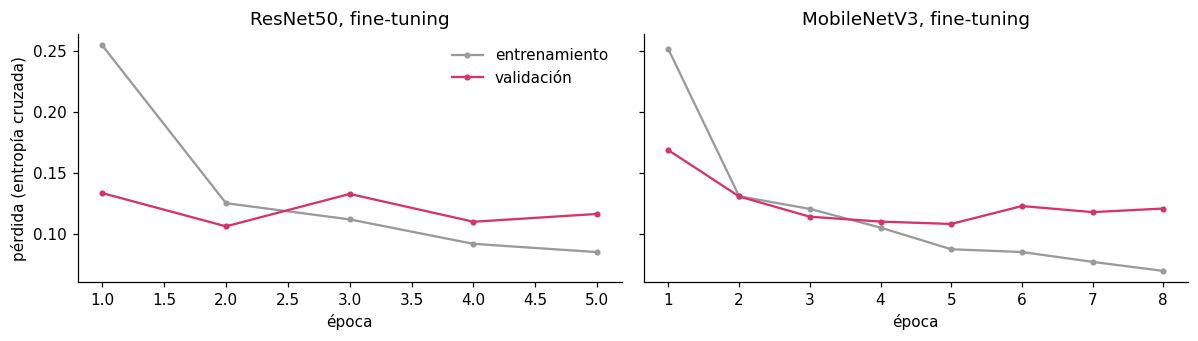

In [11]:
# Celda 10 - Curvas de entrenamiento del fine-tuning (diagnostico de sobreajuste)
fig, axes = plt.subplots(1, len(ARQS), figsize=(11, 3.2), sharey=True)
for ax, a in zip(axes, ARQS):
    h = np.array(HIST_FT[a]); ep = np.arange(1, len(h) + 1)
    ax.plot(ep, h[:, 0], "-o", ms=3, color="#9a9a9a", label="entrenamiento")
    ax.plot(ep, h[:, 1], "-o", ms=3, color="#d6336c", label="validación")
    ax.set_title(f"{a}, fine-tuning"); ax.set_xlabel("época")
axes[0].set_ylabel("pérdida (entropía cruzada)"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig("figuras/f2_curvas_ft.png", dpi=200, bbox_inches="tight"); plt.show()

### 2.4 Evaluación del mejor modelo: matriz de confusión, métricas por clase y umbral de alerta

Mejor modelo: MobileNetV3 con Fine-tuning

                precision    recall  f1-score   support

          Sana      0.998     0.998     0.998       453
Tizón temprano      0.950     0.980     0.965       252
  Tizón tardío      0.979     0.953     0.966       300

      accuracy                          0.980      1005
     macro avg      0.976     0.977     0.976      1005
  weighted avg      0.980     0.980     0.980      1005



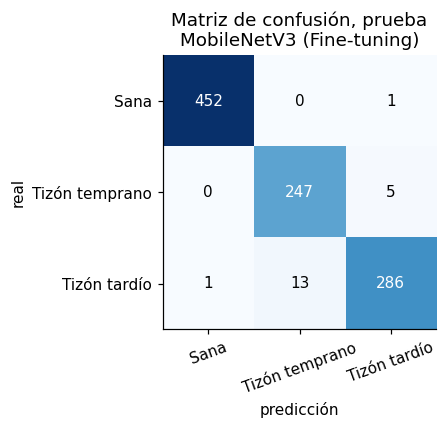

Umbral elegido en validacion (FN = 5 FP): 0,27
Prueba binaria | AUC 0,999 | VN 452 FP 1 FN 1 VP 551 | recall enferma 0,998 | recall sana 0,998
Referencia Fase 1 (MLP sobre 58.707 hojas): AUC 0,999 | recall enferma 0,998 | recall sana 0,963


In [12]:
# Celda 11 - Evaluacion por clase del mejor modelo + umbral por costo (mismo criterio de la Fase 1)
arq, est = MEJOR_A
def prob_mejor(idx):
    if est == "Fine-tuning": return prob_modelo(MODELOS_FT[arq], idx)
    return prob_cabeza(CABEZAS_FE[arq], FEATS[arq]["todas"][idx])
P_va, P_te = prob_mejor(idx_va), prob_mejor(idx_te)
pred_te = P_te.argmax(1)
print(f"Mejor modelo: {arq} con {est}\n")
print(classification_report(y_te, pred_te, target_names=[NOMBRE[c] for c in CLASES], digits=3, zero_division=0))

cm = confusion_matrix(y_te, pred_te, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels([NOMBRE[c] for c in CLASES], rotation=20); ax.set_yticklabels([NOMBRE[c] for c in CLASES])
ax.set_xlabel("predicción"); ax.set_ylabel("real"); ax.set_title(f"Matriz de confusión, prueba\n{arq} ({est})")
plt.tight_layout(); plt.savefig("figuras/f2_confusion.png", dpi=200, bbox_inches="tight"); plt.show()

# Alerta binaria (enferma = temprano o tardio) con el mismo costo de la Fase 1: FN cuesta 5 veces un FP
enf_va, enf_te = P_va[:, 1] + P_va[:, 2], P_te[:, 1] + P_te[:, 2]
yb_va, yb_te = (y_va > 0).astype(int), (y_te > 0).astype(int)
umbrales = np.linspace(0.02, 0.98, 97)
costos = [5 * ((enf_va < u) & (yb_va == 1)).sum() + ((enf_va >= u) & (yb_va == 0)).sum() for u in umbrales]
U = float(umbrales[int(np.argmin(costos))])
vn, fp, fn, vp = confusion_matrix(yb_te, (enf_te >= U).astype(int), labels=[0, 1]).ravel()
print(f"Umbral elegido en validacion (FN = 5 FP): {coma(U, 2)}")
print(f"Prueba binaria | AUC {coma(roc_auc_score(yb_te, enf_te))} | VN {vn} FP {fp} FN {fn} VP {vp} | "
      f"recall enferma {coma(vp/(vp+fn))} | recall sana {coma(vn/(vn+fp))}")
print("Referencia Fase 1 (MLP sobre 58.707 hojas): AUC 0,999 | recall enferma 0,998 | recall sana 0,963")
RESULTADOS["mejor_A_detalle"] = {"reporte": classification_report(y_te, pred_te, target_names=CLASES, output_dict=True, zero_division=0),
                                 "confusion": cm.tolist(), "umbral": U,
                                 "binaria": {"auc": float(roc_auc_score(yb_te, enf_te)), "vn": int(vn), "fp": int(fp),
                                             "fn": int(fn), "vp": int(vp)}}

### 2.5 ¿Aprende la lesión o aprende el día? Prueba dentro de los días mixtos
Es la prueba que más importa de la rama A. En la Fase 1, el MLP separaba casi perfecto en general (AUC 0,999), pero dentro del 30 de enero, un día con hojas sanas y enfermas fotografiadas en las mismas condiciones, bajaba a **AUC 0,529** (azar). Aquí se repite la prueba con la CNN: se entrena una cabeza **sin ninguna foto de esos días** y se evalúa con todas las fotos de cada día. Si la CNN mira la lesión, debería sostenerse; si mira la luz, el fondo o el estado del cultivo de ese día, debería caer como el MLP.

In [13]:
# Celda 12 - Dias mixtos fuera del entrenamiento (con el embedding congelado del mejor backbone)
DIAS_MIXTOS = [pd.Timestamp("2023-01-23"), pd.Timestamp("2023-01-30")]
FASE1_DIA = {"2023-01-23": 0.985, "2023-01-30": 0.529}
Fa = FEATS[arq]["todas"]
en_mixto = man["fecha"].isin(DIAS_MIXTOS).values
tr_m = np.where(~en_mixto & (man["split"] != "test").values)[0]
rng_m = np.random.default_rng(SEMILLA); rng_m.shuffle(tr_m)
corte = int(0.85 * len(tr_m)); tr_m, va_m = tr_m[:corte], tr_m[corte:]
cab_m, _ = entrenar_cabeza(Fa[tr_m], man["y3"].values[tr_m], Fa[va_m], man["y3"].values[va_m])
filas = []
for d in DIAS_MIXTOS:
    k = np.where(man["fecha"].values == np.datetime64(d))[0]
    if len(k) == 0: continue
    P = prob_cabeza(cab_m, Fa[k]); yk = (man["y3"].values[k] > 0).astype(int)
    auc = roc_auc_score(yk, P[:, 1] + P[:, 2]) if len(set(yk)) == 2 else float("nan")
    filas.append({"dia": f"{d:%Y-%m-%d}", "sanas": int((yk == 0).sum()), "enfermas": int(yk.sum()),
                  "AUC_CNN": auc, "AUC_MLP_fase1": FASE1_DIA.get(f"{d:%Y-%m-%d}")})
dias_tab = pd.DataFrame(filas)
print(f"Cabeza sobre {arq} congelado, entrenada SIN los dias mixtos ({len(tr_m)} fotos):")
print(dias_tab.round(3).to_string(index=False))
RESULTADOS["dias_mixtos_A"] = dias_tab.to_dict("records")

Cabeza sobre MobileNetV3 congelado, entrenada SIN los dias mixtos (4357 fotos):
       dia  sanas  enfermas  AUC_CNN  AUC_MLP_fase1
2023-01-23    381        46    0.979          0.985
2023-01-30    210        31    0.567          0.529


**¿Por qué falla el 30 de enero?** La CNN repite casi el mismo resultado del MLP (0,567 frente a 0,529). Antes de culpar al modelo, miramos las fotos: la celda siguiente muestra las 31 hojas etiquetadas como tizón tardío ese día.

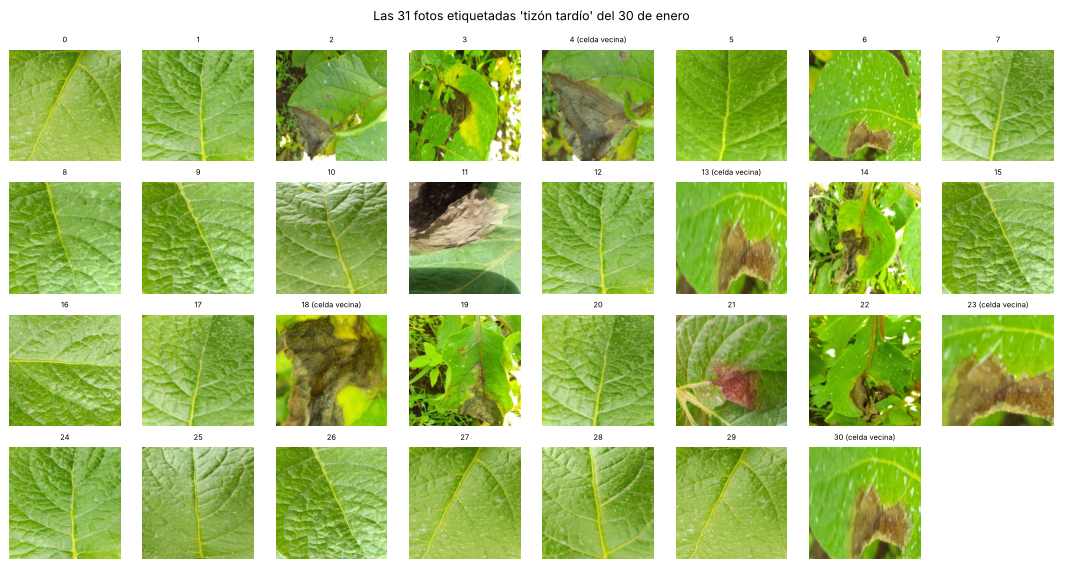

In [ ]:
# Celda 12b - Revision visual: todas las fotos "tardio" del 30 de enero
k = np.where((man["fecha"] == DIAS_MIXTOS[1]).values & (man["clase"] == "tardio").values)[0]
cols = 8; filas = int(np.ceil(len(k) / cols))
fig, axes = plt.subplots(filas, cols, figsize=(cols * 1.5, filas * 1.6))
for ax in axes.ravel(): ax.axis("off")
for j, i in enumerate(k):
    ax = axes.ravel()[j]; ax.imshow(X_u8[i].permute(1, 2, 0).numpy())
    ax.set_title(f"{j}" + (" (celda vecina)" if man["celda"][i] != CELDA_DOM else ""), fontsize=6)
plt.suptitle("Las 31 fotos etiquetadas 'tizón tardío' del 30 de enero", fontsize=10); plt.tight_layout()
plt.savefig("figuras/f2_tardio_30ene.png", dpi=200, bbox_inches="tight"); plt.show()

**Revisión visual (hecha por el equipo, foto por foto):** solo **13 de las 31** fotos "tardío" del 30 de enero muestran una lesión visible (números 2, 3, 4, 6, 11, 13, 14, 18, 19, 21, 22, 23 y 30). Las otras **18** son primeros planos de hoja verde, indistinguibles de las fotos sanas del mismo día. La etiqueta del dataset viene de la carpeta (planta o lote con tizón), no de que la lesión aparezca en la foto.

Eso cambia la lectura: el 30 de enero no mide si la red ve la lesión, sino cuánto ruido de etiqueta tiene ese día. Si un modelo pusiera perfectamente arriba las 13 con lesión y no pudiera separar las 18 restantes de las sanas, su AUC sería cercano a 13/31 + 18/31 x 0,5 = 0,71. Ese es el techo práctico del día para cualquier modelo de imagen, y lo dejamos como limitación del dataset en el informe. El 23 de enero, en cambio, 45 de las 46 fotos tardío muestran la lesión, y la CNN llega a 0,979.

### 2.6 Grad-CAM: ¿dónde mira la red?
Grad-CAM (Selvaraju et al., 2017) pondera los mapas de activación de la última capa convolucional por el gradiente de la clase predicha y muestra qué zonas de la foto empujaron la decisión. Además de mirar ejemplos, se cuantifica: qué fracción de la "energía" del mapa cae sobre píxeles parduzcos (los mismos que la Fase 1 contaba como necrosis) frente a lo que se esperaría si el mapa fuera uniforme. Si la razón es mayor que 1 en las hojas enfermas, la red está atendiendo a las lesiones.

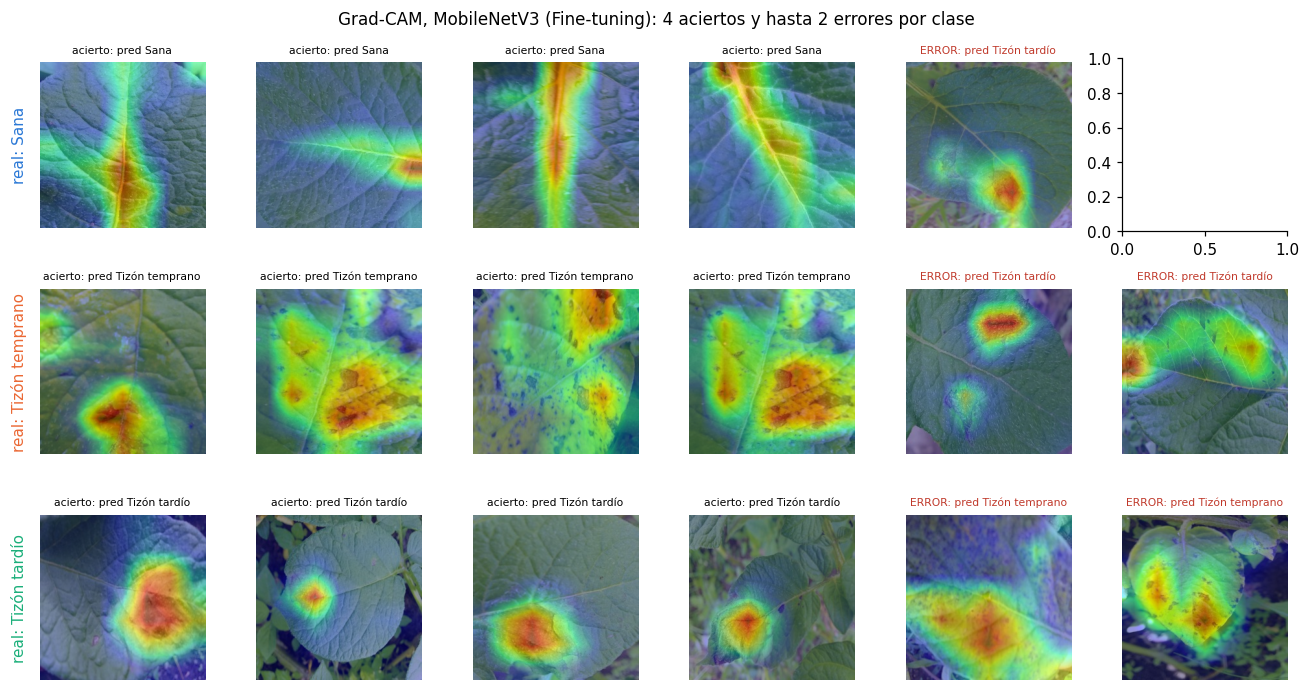

Razon de atencion sobre zonas parduzcas (1 = como si mirara al azar):
  Sana            mediana 1,21 | fotos 22
  Tizón temprano  mediana 1,10 | fotos 102
  Tizón tardío    mediana 2,66 | fotos 120


In [14]:
# Celda 13 - Grad-CAM sobre el mejor modelo (aciertos y errores por clase) + medida cuantitativa
if est == "Fine-tuning":
    red = MODELOS_FT[arq]; bb_g = red[0]
else:
    bb_g = FEATS[arq]["bb"]; red = nn.Sequential(bb_g, CABEZAS_FE[arq]).to(DEVICE).eval()
capa = bb_g.layer4 if arq == "ResNet50" else bb_g.features[-1]
acts, grads = {}, {}
h1 = capa.register_forward_hook(lambda m, i, o: acts.__setitem__("a", o))
h2 = capa.register_full_backward_hook(lambda m, gi, go: grads.__setitem__("g", go[0]))

def grad_cam(k):
    req = [p.requires_grad for p in red.parameters()]
    for p in red.parameters(): p.requires_grad_(True)
    x = tf_eval(X_u8[k]).unsqueeze(0).to(DEVICE).requires_grad_(True)
    red.zero_grad(); logit = red(x); c = int(logit.argmax(1)); logit[0, c].backward()
    A, G = acts["a"][0].detach(), grads["g"][0].detach()
    cam = torch.relu((G.mean((1, 2))[:, None, None] * A).sum(0))
    cam = F.interpolate(cam[None, None], size=LADO, mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    for p, r in zip(red.parameters(), req): p.requires_grad_(r)
    return cam.cpu().numpy(), c

def mascara_lesion(k):     # mismo criterio de "necrosis" de la Fase 1: pixel mas rojo que verde y que azul
    a = X_u8[k].int(); return ((a[0] > a[1]) & (a[0] > a[2])).numpy()

pred_lbl = P_te.argmax(1)
fig, axes = plt.subplots(3, 6, figsize=(12, 6.4))
for i in range(3):
    bien = idx_te[(y_te == i) & (pred_lbl == i)][:4]; mal = idx_te[(y_te == i) & (pred_lbl != i)][:2]
    for j, k in enumerate(list(bien) + list(mal)):
        cam, c = grad_cam(k); ax = axes[i, j]
        ax.imshow(X_u8[k].permute(1, 2, 0).numpy()); ax.imshow(cam, cmap="jet", alpha=0.42); ax.axis("off")
        ok_ = "acierto" if c == i else "ERROR"
        ax.set_title(f"{ok_}: pred {NOMBRE[CLASES[c]]}", fontsize=7, color="black" if c == i else "#c0392b")
    axes[i, 0].text(-20, 128, f"real: {NOMBRE[CLASES[i]]}", rotation=90, va="center", ha="right", color=COLOR[CLASES[i]])
plt.suptitle(f"Grad-CAM, {arq} ({est}): 4 aciertos y hasta 2 errores por clase", fontsize=11)
plt.tight_layout(); plt.savefig("figuras/f2_gradcam.png", dpi=200, bbox_inches="tight"); plt.show()

# Cuantitativo: energia del CAM sobre pixeles parduzcos / fraccion de pixeles parduzcos
razones = {c: [] for c in CLASES}
for k in idx_te[: (60 if SMOKE else 450)]:
    cam, _ = grad_cam(k); msk = mascara_lesion(k)
    if msk.mean() < 0.01: continue
    razones[CLASES[man["y3"].values[k]]].append((cam * msk).sum() / cam.sum() / msk.mean())
h1.remove(); h2.remove()
print("Razon de atencion sobre zonas parduzcas (1 = como si mirara al azar):")
for c in CLASES:
    r = np.array(razones[c])
    if len(r): print(f"  {NOMBRE[c]:15} mediana {coma(np.median(r), 2)} | fotos {len(r)}")
RESULTADOS["gradcam_razon"] = {c: float(np.median(v)) if len(v) else None for c, v in razones.items()}

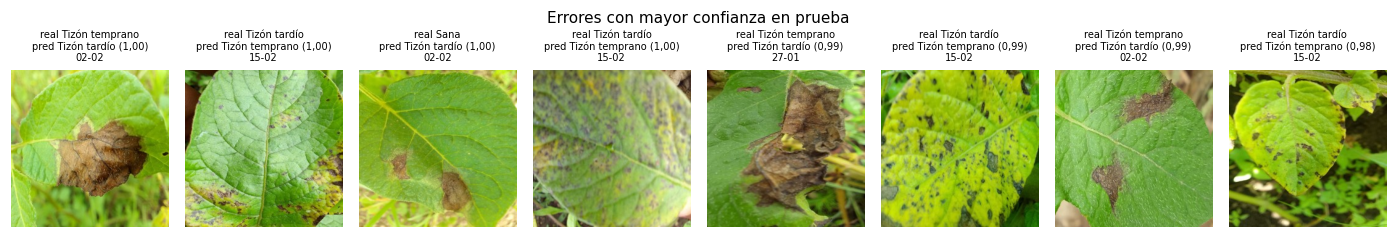

Confusiones en prueba (real -> predicho): Counter({('tardio', 'temprano'): 4, ('temprano', 'tardio'): 3, ('sana', 'tardio'): 1})


In [15]:
# Celda 14 - Galeria de los errores mas confiados (que se equivoca y por que)
conf_err = [(P_te[i, pred_lbl[i]], idx_te[i], y_te[i], pred_lbl[i]) for i in range(len(idx_te)) if pred_lbl[i] != y_te[i]]
conf_err = sorted(conf_err, reverse=True)[:8]
if conf_err:
    fig, axes = plt.subplots(1, len(conf_err), figsize=(1.6 * len(conf_err), 2.3))
    axes = np.atleast_1d(axes)
    for ax, (p, k, yr, yp) in zip(axes, conf_err):
        ax.imshow(X_u8[k].permute(1, 2, 0).numpy()); ax.axis("off")
        ax.set_title(f"real {NOMBRE[CLASES[yr]]}\npred {NOMBRE[CLASES[yp]]} ({coma(p, 2)})\n{man['fecha'][k]:%d-%m}", fontsize=6.5)
    plt.suptitle("Errores con mayor confianza en prueba", fontsize=10); plt.tight_layout()
    plt.savefig("figuras/f2_errores.png", dpi=200, bbox_inches="tight"); plt.show()
print("Confusiones en prueba (real -> predicho):", Counter((CLASES[a], CLASES[b]) for _, _, a, b in conf_err))

**Lectura de la rama A.**
- **Las cuatro combinaciones superan al MLP de la Fase 1 en falsas alarmas.** En prueba (1.005 fotos), el F1 macro va de 0,959 (ResNet50 congelada) a 0,976 (MobileNetV3 afinada). El mejor modelo, elegido en validación (F1 0,981), es **MobileNetV3 con fine-tuning**. Con el mismo criterio de costo de la Fase 1 (un FN vale 5 FP, umbral 0,27 elegido en validación), la alerta binaria queda en VN 452, FP 1, FN 1, VP 551. El recall de sanas sube de 0,963 (MLP) a 0,998: las falsas alarmas pasan del 3,7 % al 0,2 % de las hojas sanas.
- **FE o FT, con evidencia.** El fine-tuning mejora poco: +1,3 puntos de F1 en ResNet50 y +0,5 en MobileNetV3, a cambio de 6 a 18 veces más tiempo de entrenamiento y de parar en la época 5 a 8 porque la validación empieza a subir (curvas de la celda 10). Con similitud media con ImageNet y ~4.700 fotos, el backbone congelado ya resuelve casi todo; afinar los últimos bloques ajusta los detalles que separan los dos tizones. Nos quedamos con FT porque gana en validación y el costo es de minutos.
- **ResNet50 o MobileNetV3.** Empatan en exactitud, pero MobileNetV3 tiene 8 veces menos parámetros (3,0 M frente a 23,5 M) y pesa 11,9 MB frente a 94 MB. En la T4, con una sola imagen, la latencia es similar (6,2 y 6,4 ms) porque la GPU está casi ociosa; la ventaja de MobileNetV3 aparece en CPU y en celulares, que es el escenario de la Fase 3.
- **Errores.** Casi todos son entre los dos tizones (13 tardíos leídos como tempranos y 5 al revés), y para el cliente es el error menos grave porque la hoja igual queda marcada como enferma. Solo hay 2 errores entre sana y enferma: 1 sana leída como tardío y 1 tardío leída como sana.
- **¿Mira la lesión?** En las hojas con tizón tardío, Grad-CAM concentra 2,66 veces más atención sobre los píxeles parduzcos de lo esperado al azar. En temprano la razón es 1,10, porque sus manchas son pequeñas y oscuras y la máscara de color las capta mal; en los ejemplos de la celda 13 se ve que la red se posa sobre esas manchas. En las sanas mira sobre todo la nervadura central, un patrón que comparten todos los primeros planos de hoja sana. El 23 de enero, sin haber visto ninguna foto de ese día, la CNN llega a 0,979. El 30 de enero cae a 0,567, y la revisión visual de arriba muestra que el problema son las etiquetas, no la red.

## 3. Rama B - Secuencia: RNN, LSTM y GRU sobre 25 años de clima

**Tarea:** con los últimos 14 días de clima de la celda de Mbeya, predecir si en los **próximos 3 días** se completa un **periodo de Hutton** (dos días seguidos con mínima >= 10 °C y al menos 6 horas con humedad >= 90 %). Es el criterio que usa el servicio de alertas de tizón tardío del Reino Unido (Met Office / AHDB) y le dice al extensionista **cuándo** salir a revisar los lotes, antes de que aparezcan las lesiones.

**Por qué una red recurrente y no la tabla de la Fase 1 o un ARIMA.** El riesgo no depende del clima de un solo día sino de la **trayectoria**: varios días húmedos seguidos, una noche que no baja de 10 °C, la lluvia que se acumula. Una red recurrente lee los 14 días en orden y guarda memoria de lo que pasó antes. Un ARIMA modela una sola variable con relaciones lineales; aquí hay 8 variables que interactúan (humedad alta **y** temperatura mínima alta), y la salida es un evento, no un valor.

**Un hallazgo del EDA que cambia la lectura.** En la celda de Mbeya, de diciembre a abril el criterio de Hutton se cumple prácticamente todos los días (la temporada de lluvias en el altiplano es, toda ella, clima de tizón; además el reanálisis tiende a sobrestimar la humedad). Por eso el pronóstico se evalúa en todo el año **y por separado en los meses de transición** (mayo-junio y septiembre-noviembre), que es donde el extensionista realmente necesita que le avisen cuándo empieza y cuándo termina el riesgo.

Se usa la celda dominante (-9,0 / 33,75), donde caen casi todas las fotos con GPS. Partición **cronológica**: entrenamiento 2001-2016, validación 2017-2019, prueba 2020-2025. Así el año 2023, el de las fotos, queda en prueba: la red nunca vio el clima de la campaña.

### 3.1 Análisis exploratorio de la serie

Serie: 9131 dias, de 2001-01-01 a 2025-12-31
             mean   std    min     max
t_media     16.49  2.12   8.76   21.64
t_min       11.45  2.85   1.80   17.04
t_max       23.37  2.44  13.19   31.02
hr_media    79.49  8.15  45.19   96.39
hr_max      99.27  1.73  75.72  100.00
horas_hr90  11.62  3.72   0.00   22.00
lluvia_mm    4.41  9.09   0.00  157.38
viento_ms    0.80  0.30   0.22    2.33


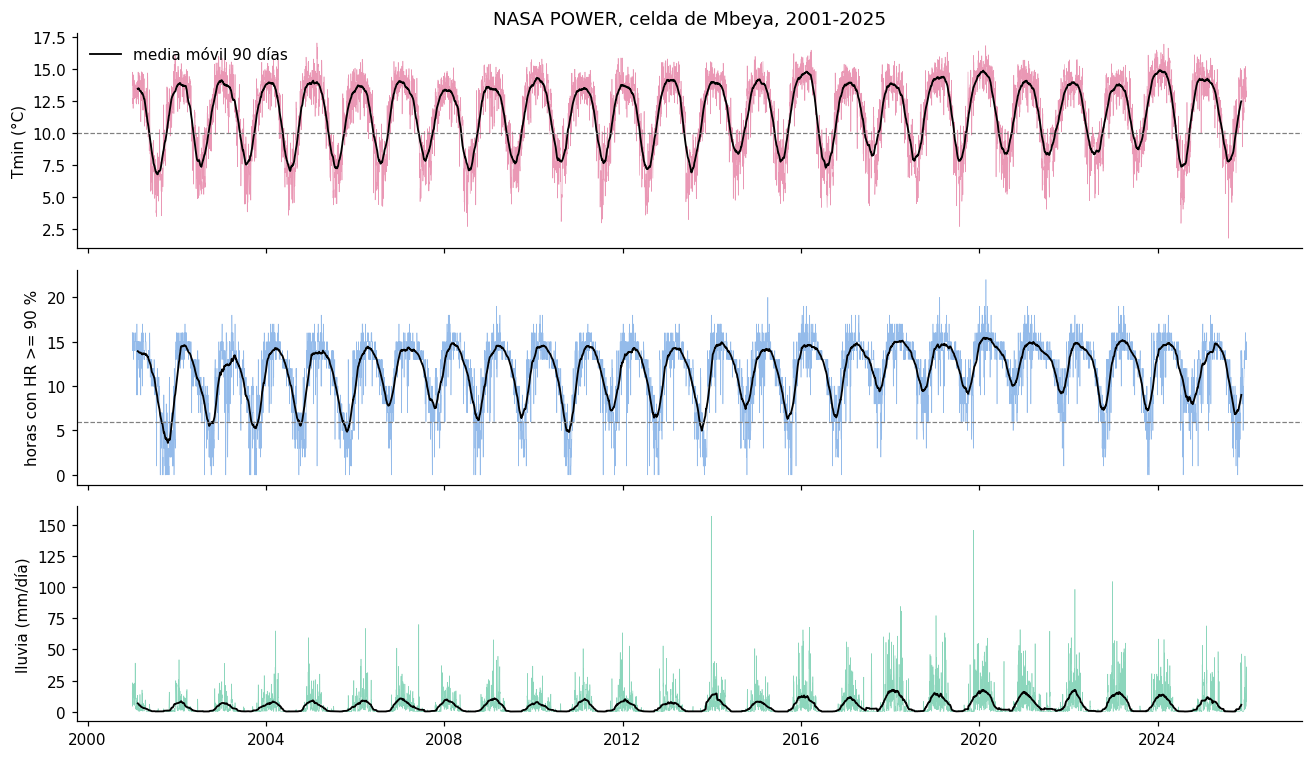

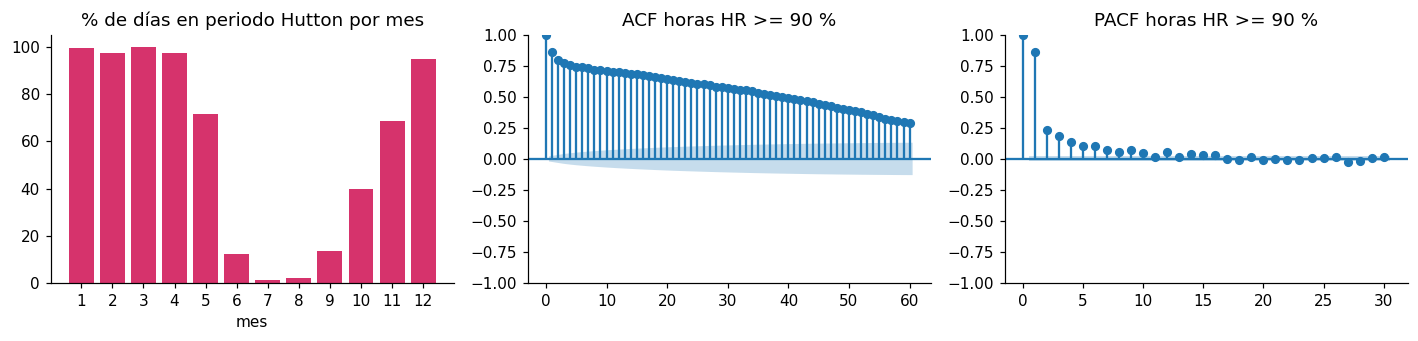

% periodo Hutton por mes: {1: 99.4, 2: 97.5, 3: 100.0, 4: 97.2, 5: 71.4, 6: 12.4, 7: 1.5, 8: 2.1, 9: 13.6, 10: 39.9, 11: 68.5, 12: 94.7}
Dias con lluvia atipica (> Q3 + 3 IQR): 510


In [16]:
# Celda 15 - EDA de la serie: tendencia, estacionalidad, eventos Hutton, ACF/PACF
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
s = clima[clima["celda"] == CELDA_DOM].set_index("fecha").sort_index()
print(f"Serie: {len(s)} dias, de {s.index.min():%Y-%m-%d} a {s.index.max():%Y-%m-%d}")
print(s[VARS].describe().T[["mean", "std", "min", "max"]].round(2).to_string())

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, v, col, et in zip(axes, ["t_min", "horas_hr90", "lluvia_mm"], ["#d6336c", "#2a78d6", "#1baf7a"],
                          ["Tmin (°C)", "horas con HR >= 90 %", "lluvia (mm/día)"]):
    ax.plot(s.index, s[v], color=col, lw=0.4, alpha=0.5)
    ax.plot(s.index, s[v].rolling(90, center=True).mean(), color="black", lw=1.2, label="media móvil 90 días")
    ax.set_ylabel(et)
axes[0].axhline(10, color="gray", ls="--", lw=0.8); axes[1].axhline(6, color="gray", ls="--", lw=0.8)
axes[0].legend(frameon=False, loc="upper left"); axes[0].set_title("NASA POWER, celda de Mbeya, 2001-2025")
plt.tight_layout(); plt.savefig("figuras/f2_serie.png", dpi=200, bbox_inches="tight"); plt.show()

mes = s.groupby(s.index.month)[["dia_hutton", "periodo_hutton"]].mean() * 100
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].bar(mes.index, mes["periodo_hutton"], color="#d6336c")
ax[0].set_xticks(range(1, 13)); ax[0].set_title("% de días en periodo Hutton por mes"); ax[0].set_xlabel("mes")
plot_acf(s["horas_hr90"], lags=60, ax=ax[1], title="ACF horas HR >= 90 %"); plot_pacf(s["horas_hr90"], lags=30, ax=ax[2], title="PACF horas HR >= 90 %", method="ywm")
plt.tight_layout(); plt.savefig("figuras/f2_estacionalidad.png", dpi=200, bbox_inches="tight"); plt.show()
print("% periodo Hutton por mes:", mes["periodo_hutton"].round(1).to_dict())
q1, q3 = s["lluvia_mm"].quantile([.25, .75]); print("Dias con lluvia atipica (> Q3 + 3 IQR):", int((s["lluvia_mm"] > q3 + 3 * (q3 - q1)).sum()))

**Lo que decide este EDA.** La serie tiene una estacionalidad fuerte (temporada de lluvias de noviembre a abril, que es también la temporada de siembra y de las fotos) y una autocorrelación que se extiende varios días: la humedad de hoy se parece a la de ayer y a la de hace una semana. Eso justifica una ventana de 14 días como referencia (dos semanas de historia, el horizonte con el que un extensionista planea visitas) y añadir el día del año como variable exógena (seno y coseno), para que la red sepa en qué parte de la temporada está.

In [17]:
# Celda 16 - Ventaneo, etiqueta a 3 dias y particion cronologica
HORIZONTE = 3
s = s.copy()
s["sen_doy"], s["cos_doy"] = np.sin(2 * np.pi * s.index.dayofyear / 365.25), np.cos(2 * np.pi * s.index.dayofyear / 365.25)
FEATS_B = VARS + ["sen_doy", "cos_doy"]
fut = pd.concat([s["periodo_hutton"].shift(-h) for h in range(1, HORIZONTE + 1)], axis=1)
s["y_cls"] = fut.max(axis=1)                      # se completa un periodo Hutton en d+1..d+3
s["y_reg"] = s["horas_hr90"].shift(-1)            # horas con HR >= 90 % manana
anio = s.index.year
scaler_B = StandardScaler().fit(s.loc[anio <= 2016, FEATS_B])
Z = scaler_B.transform(s[FEATS_B]).astype(np.float32)

def ventanas(W):
    idx = np.arange(W - 1, len(s) - HORIZONTE)
    X = np.stack([Z[i - W + 1:i + 1] for i in idx])
    return X, s["y_cls"].values[idx].astype(np.float32), s["y_reg"].values[idx].astype(np.float32), s.index[idx]

def particion(W):
    X, yc, yr, fechas = ventanas(W); a = fechas.year
    m = {"train": a <= 2016, "val": (a >= 2017) & (a <= 2019), "test": a >= 2020}
    return {k: (torch.tensor(X[v]), torch.tensor(yc[v]).unsqueeze(1), torch.tensor(yr[v]).unsqueeze(1), fechas[v])
            for k, v in m.items()}

W = 14
D14 = particion(W)
for k, (X, yc, yr, f) in D14.items():
    print(f"{k:5} | {len(X):5} ventanas {tuple(X.shape)} | {f.min():%Y}-{f.max():%Y} | positivos {yc.mean().item():.1%}")
pos_w = float((D14["train"][1] == 0).sum() / max((D14["train"][1] == 1).sum(), 1))
print("pos_weight para la perdida:", round(pos_w, 2))

train |  5831 ventanas (5831, 14, 10) | 2001-2016 | positivos 60.9%
val   |  1095 ventanas (1095, 14, 10) | 2017-2019 | positivos 71.0%
test  |  2189 ventanas (2189, 14, 10) | 2020-2025 | positivos 67.5%
pos_weight para la perdida: 0.64


In [18]:
# Celda 17 - Lineas base: persistencia, climatologia mensual y regresion logistica sobre la ventana aplanada
def met_bin(y, p, u=None):
    y = np.asarray(y).ravel().astype(int); p = np.asarray(p).ravel()
    out = {"AUC": roc_auc_score(y, p) if len(set(y)) == 2 else np.nan, "PR_AUC": average_precision_score(y, p)}
    if u is not None:
        yh = (p >= u).astype(int)
        out.update({"recall": recall_score(y, yh, zero_division=0), "precision": precision_score(y, yh, zero_division=0),
                    "F1": f1_score(y, yh, zero_division=0)})
    return out

def umbral_f1(y, p):
    us = np.linspace(0.05, 0.95, 91); return float(us[np.argmax([f1_score(np.ravel(y), np.ravel(p) >= u, zero_division=0) for u in us])])

yte_c = D14["test"][1].numpy().ravel(); f_te = D14["test"][3]
base = {}
base["persistencia (Hutton hoy)"] = s.loc[f_te, "dia_hutton"].values.astype(float)
clim_mes = s[anio <= 2016].groupby(s[anio <= 2016].index.month)["y_cls"].mean()
base["climatología mensual"] = clim_mes.reindex(f_te.month).values
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(D14["train"][0].reshape(len(D14["train"][0]), -1), D14["train"][1].ravel())
p_lr_va = lr.predict_proba(D14["val"][0].reshape(len(D14["val"][0]), -1))[:, 1]
base["logística (ventana aplanada)"] = lr.predict_proba(D14["test"][0].reshape(len(D14["test"][0]), -1))[:, 1]
u_lr = umbral_f1(D14["val"][1].numpy(), p_lr_va)
TAB_B = {}
for k, p in base.items():
    TAB_B[k] = met_bin(yte_c, p, 0.5 if k != "logística (ventana aplanada)" else u_lr)
print(pd.DataFrame(TAB_B).T.round(3).to_string())

                                AUC  PR_AUC  recall  precision     F1
persistencia (Hutton hoy)     0.895   0.915   0.919      0.937  0.928
climatología mensual          0.943   0.967   0.826      0.960  0.888
logística (ventana aplanada)  0.970   0.986   0.958      0.901  0.929


### 3.2 Tres celdas recurrentes con hiperparámetros comparables
Estado oculto 64, tasa de aprendizaje 0,001, lote de 32, parada anticipada sobre la pérdida de validación (paciencia 8) y `BCEWithLogitsLoss` con peso para la clase positiva (la red entrega un logit, igual que el MLP de la Fase 1, sin sigmoide doble). La RNN simple entra **como contraste**: misma tarea, mismos datos, sin compuertas. Durante el entrenamiento se guarda la norma del gradiente de la matriz recurrente $W_{hh}$ en cada época.

In [19]:
# Celda 18 - RNN simple vs LSTM vs GRU (clasificacion Hutton a 3 dias)
class Recurrente(nn.Module):
    def __init__(self, tipo, n_feat=len(FEATS_B), oculta=64):
        super().__init__()
        self.tipo = tipo
        self.rec = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[tipo](n_feat, oculta, batch_first=True)
        self.cabeza = nn.Linear(oculta, 1)                 # logit
    def embedding(self, x):
        salida, _ = self.rec(x); return salida[:, -1, :]   # estado oculto del ultimo dia = z_seq
    def forward(self, x): return self.cabeza(self.embedding(x))

def entrenar_rec(tipo, D, tarea="cls", semilla=SEMILLA, epocas=8 if SMOKE else 60, paciencia=8, bs=32):
    fijar_semilla(semilla); m = Recurrente(tipo).to(DEVICE); t0 = time.time()
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_w], device=DEVICE)) if tarea == "cls" else nn.MSELoss()
    col = 1 if tarea == "cls" else 2
    def objetivo(sp): return D[sp][col].to(DEVICE) / (1 if tarea == "cls" else 24.0)
    Xtr, ytr, Xva, yva = D["train"][0].to(DEVICE), objetivo("train"), D["val"][0].to(DEVICE), objetivo("val")
    mejor, estado, sin_mejora, hist = 1e9, None, 0, []
    for ep in range(epocas):
        m.train(); perm = torch.randperm(len(Xtr), device=DEVICE); gn = []
        for j in range(0, len(Xtr), bs):
            b = perm[j:j + bs]; opt.zero_grad(); loss = crit(m(Xtr[b]), ytr[b]); loss.backward()
            gn.append(m.rec.weight_hh_l0.grad.norm().item())
            nn.utils.clip_grad_norm_(m.parameters(), 5.0); opt.step()
        m.eval()
        with torch.no_grad(): lv = crit(m(Xva), yva).item()
        hist.append({"val": lv, "grad_Whh": float(np.mean(gn))})
        if lv < mejor - 1e-5: mejor, estado, sin_mejora = lv, copy.deepcopy(m.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: break
    m.load_state_dict(estado); m.eval()
    return m, hist, time.time() - t0

@torch.no_grad()
def prob_rec(m, X): return torch.sigmoid(m(X.to(DEVICE))).cpu().numpy().ravel()

CELDAS = ["RNN", "LSTM", "GRU"]
REC, HIST_REC = {}, {}
for tipo in CELDAS:
    m, hist, seg = entrenar_rec(tipo, D14)
    REC[tipo], HIST_REC[tipo] = m, hist
    u = umbral_f1(D14["val"][1].numpy(), prob_rec(m, D14["val"][0]))
    TAB_B[tipo] = {**met_bin(yte_c, prob_rec(m, D14["test"][0]), u), "umbral": u,
                   "parametros": sum(p.numel() for p in m.parameters()), "epocas": len(hist), "segundos": seg}
tabla_B = pd.DataFrame(TAB_B).T
print("Rama B, prueba 2020-2025 (alerta Hutton en los proximos 3 dias):")
print(tabla_B.round(3).to_string())
RESULTADOS["rama_B"] = tabla_B.round(4).reset_index().rename(columns={"index": "modelo"}).to_dict("records")

Rama B, prueba 2020-2025 (alerta Hutton en los proximos 3 dias):
                                AUC  PR_AUC  recall  precision     F1  umbral  parametros  epocas  segundos
persistencia (Hutton hoy)     0.895   0.915   0.919      0.937  0.928     NaN         NaN     NaN       NaN
climatología mensual          0.943   0.967   0.826      0.960  0.888     NaN         NaN     NaN       NaN
logística (ventana aplanada)  0.970   0.986   0.958      0.901  0.929     NaN         NaN     NaN       NaN
RNN                           0.975   0.989   0.913      0.959  0.936    0.55      4929.0    24.0    11.973
LSTM                          0.974   0.988   0.920      0.952  0.936    0.43     19521.0    16.0     8.880
GRU                           0.976   0.989   0.917      0.958  0.937    0.51     14657.0    16.0     8.459


In [20]:
# Celda 18b - Donde el pronostico importa: meses de transicion (inicio y fin de la temporada de lluvias)
# En plena temporada (dic-abr) el criterio de Hutton se cumple casi todos los dias y cualquier modelo acierta;
# la decision dificil es cuando empieza y cuando termina el riesgo.
mes_te = f_te.month
TRANS = np.isin(mes_te, [5, 6, 9, 10, 11])
print(f"% de dias con alerta Hutton por mes (toda la serie):", (s.groupby(s.index.month)["y_cls"].mean() * 100).round(0).to_dict())
print(f"Dias de prueba en meses de transicion (may, jun, sep, oct, nov): {TRANS.sum()} | positivos {yte_c[TRANS].mean():.1%}\n")
trans = {}
for k, p in base.items(): trans[k] = met_bin(yte_c[TRANS], np.asarray(p)[TRANS])
for tipo in CELDAS: trans[tipo] = met_bin(yte_c[TRANS], prob_rec(REC[tipo], D14["test"][0])[TRANS])
tabla_trans = pd.DataFrame(trans).T
print("Prueba 2020-2025, solo meses de transicion:"); print(tabla_trans.round(3).to_string())
RESULTADOS["rama_B_transicion"] = tabla_trans.round(4).reset_index().rename(columns={"index": "modelo"}).to_dict("records")

% de dias con alerta Hutton por mes (toda la serie): {1: 100.0, 2: 100.0, 3: 100.0, 4: 99.0, 5: 80.0, 6: 18.0, 7: 2.0, 8: 5.0, 9: 28.0, 10: 54.0, 11: 83.0, 12: 98.0}
Dias de prueba en meses de transicion (may, jun, sep, oct, nov): 912 | positivos 59.6%

Prueba 2020-2025, solo meses de transicion:
                                AUC  PR_AUC
persistencia (Hutton hoy)     0.808   0.809
climatología mensual          0.770   0.783
logística (ventana aplanada)  0.903   0.935
RNN                           0.915   0.945
LSTM                          0.909   0.942
GRU                           0.919   0.949


In [21]:
# Celda 19 - Robustez a la semilla (3 semillas por celda) y eleccion GRU vs LSTM
semillas = [SEMILLA] if SMOKE else [SEMILLA, 7, 2026]
rob = []
for tipo in CELDAS:
    for sd in semillas:
        if sd == SEMILLA: m, seg = REC[tipo], TAB_B[tipo]["segundos"]     # ya entrenada en la celda anterior
        else: m, _, seg = entrenar_rec(tipo, D14, semilla=sd)
        rob.append({"celda": tipo, "semilla": sd, "AUC_val": met_bin(D14["val"][1].numpy(), prob_rec(m, D14["val"][0]))["AUC"],
                    "AUC_test": met_bin(yte_c, prob_rec(m, D14["test"][0]))["AUC"], "segundos": seg})
rob = pd.DataFrame(rob)
res_rob = rob.groupby("celda")[["AUC_val", "AUC_test", "segundos"]].agg(["mean", "std"]).round(3)
print(res_rob.to_string())
MEJOR_B = rob[rob["celda"] != "RNN"].groupby("celda")["AUC_val"].mean().idxmax()   # se decide en VALIDACION
print(f"\nCelda elegida para la fusion (mejor AUC medio en validacion): {MEJOR_B}")
RESULTADOS["rama_B_semillas"] = rob.round(4).to_dict("records"); RESULTADOS["mejor_B"] = MEJOR_B
torch.save(REC[MEJOR_B].state_dict(), f"pesos/{MEJOR_B.lower()}_hutton.pth")
for tipo in CELDAS: torch.save(REC[tipo].state_dict(), f"pesos/rec_{tipo.lower()}_w14.pth")

      AUC_val        AUC_test        segundos       
         mean    std     mean    std     mean    std
celda                                               
GRU     0.982  0.000    0.976  0.001    8.706  1.020
LSTM    0.980  0.001    0.974  0.001    8.278  0.531
RNN     0.981  0.000    0.974  0.001   10.463  2.056

Celda elegida para la fusion (mejor AUC medio en validacion): GRU


### 3.3 Regresión: horas de humedad >= 90 % mañana (RMSE, MAE y MAPE)
La alerta Hutton es un evento, pero la actividad pide también comparar con métricas de error de pronóstico. La misma arquitectura se entrena para predecir **cuántas horas con HR >= 90 %** tendrá el día siguiente (de 0 a 24). El MAPE se calcula solo en los días con valor real mayor que cero, porque con ceros se divide por cero; se reporta también el MAE, que no tiene ese problema.

                    RMSE_h  MAE_h  MAPE_%_(y>0)
persistencia (hoy)    1.91   1.26         14.05
RNN                   1.62   1.13         13.52
LSTM                  1.62   1.13         13.52
GRU                   1.63   1.15         13.64


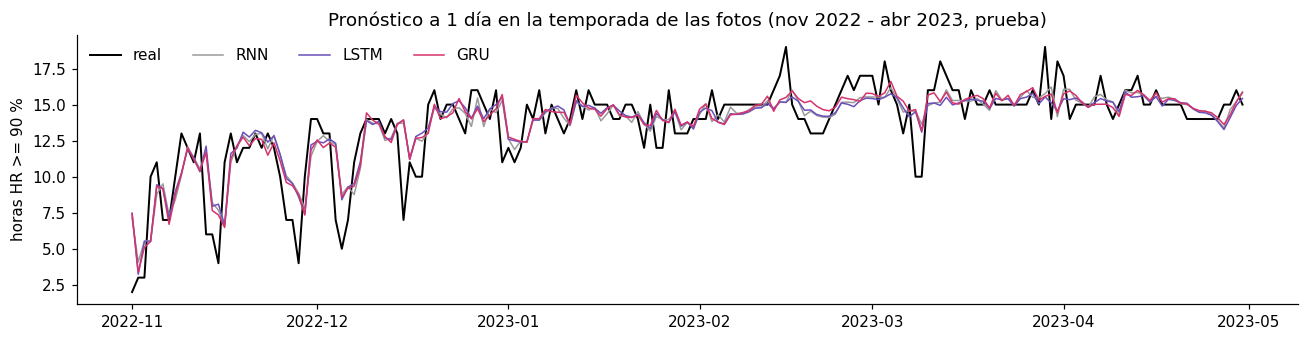

In [22]:
# Celda 20 - Regresion de horas_hr90 de manana con las tres celdas + persistencia
yte_r = D14["test"][2].numpy().ravel()
def met_reg(y, p):
    nz = y > 0
    return {"RMSE_h": float(np.sqrt(mean_squared_error(y, p))), "MAE_h": float(mean_absolute_error(y, p)),
            "MAPE_%_(y>0)": float(np.mean(np.abs((y[nz] - p[nz]) / y[nz])) * 100)}
REG = {"persistencia (hoy)": met_reg(yte_r, s.loc[f_te, "horas_hr90"].values)}
PRED_REG = {}
for tipo in CELDAS:
    m, _, _ = entrenar_rec(tipo, D14, tarea="reg")
    with torch.no_grad(): p = (m(D14["test"][0].to(DEVICE)).cpu().numpy().ravel() * 24).clip(0, 24)
    PRED_REG[tipo] = p; REG[tipo] = met_reg(yte_r, p)
tabla_reg = pd.DataFrame(REG).T
print(tabla_reg.round(2).to_string())
RESULTADOS["rama_B_regresion"] = tabla_reg.round(3).reset_index().rename(columns={"index": "modelo"}).to_dict("records")

ventana = (f_te >= "2022-11-01") & (f_te <= "2023-04-30")
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(f_te[ventana], yte_r[ventana], color="black", lw=1.3, label="real")
for tipo in CELDAS: ax.plot(f_te[ventana], PRED_REG[tipo][ventana], color=COL_MOD[tipo], lw=1, label=tipo)
ax.set_ylabel("horas HR >= 90 %"); ax.set_title("Pronóstico a 1 día en la temporada de las fotos (nov 2022 - abr 2023, prueba)")
ax.legend(frameon=False, ncol=4); plt.tight_layout(); plt.savefig("figuras/f2_regresion.png", dpi=200, bbox_inches="tight"); plt.show()

### 3.4 Evidencia del desvanecimiento del gradiente
Dos evidencias, como pide la actividad:
1. **Cuánto gradiente llega a cada día de la ventana.** Con una ventana larga de 60 días se mide la magnitud media de $\partial L / \partial x_t$ para cada paso. En una RNN simple el gradiente es un producto de jacobianos y decae exponencialmente hacia el pasado; las compuertas de LSTM y GRU abren una "autopista" que lo conserva.
2. **La norma del gradiente de $W_{hh}$ durante el entrenamiento**, registrada en la celda 18.

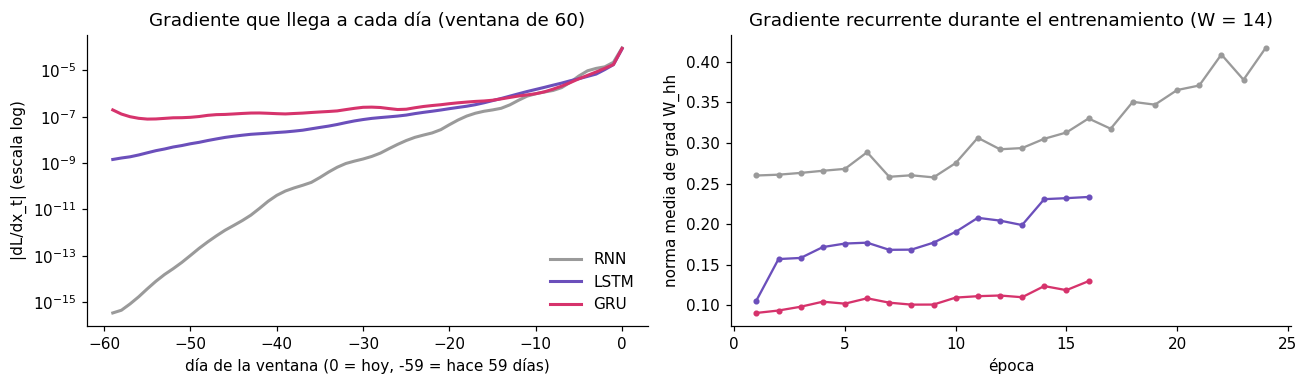

RNN   | hoy 9.34e-05 | hace 59 dias 3.42e-16 | caida x2.7e+11
LSTM  | hoy 8.46e-05 | hace 59 dias 1.43e-09 | caida x5.9e+04
GRU   | hoy 8.87e-05 | hace 59 dias 1.97e-07 | caida x4.5e+02


In [23]:
# Celda 21 - |dL/dx_t| por paso con ventana de 60 dias + norma del gradiente durante el entrenamiento
D60 = particion(60); perfiles = {}
Xb = D60["train"][0][:512].to(DEVICE).clone().requires_grad_(True); yb = D60["train"][1][:512].to(DEVICE)
for tipo in CELDAS:
    m, _, _ = entrenar_rec(tipo, D60, epocas=3 if SMOKE else 15)
    m.train()                                    # cuDNN solo deja hacer backward de RNN en modo train
    if Xb.grad is not None: Xb.grad.zero_()
    nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_w], device=DEVICE))(m(Xb), yb).backward()
    perfiles[tipo] = Xb.grad.abs().mean((0, 2)).detach().cpu().numpy()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for tipo in CELDAS:
    ax[0].semilogy(np.arange(-59, 1), perfiles[tipo], color=COL_MOD[tipo], lw=2, label=tipo)
    g = [h["grad_Whh"] for h in HIST_REC[tipo]]; ax[1].plot(range(1, len(g) + 1), g, "-o", ms=3, color=COL_MOD[tipo], label=tipo)
ax[0].set_xlabel("día de la ventana (0 = hoy, -59 = hace 59 días)"); ax[0].set_ylabel("|dL/dx_t| (escala log)")
ax[0].set_title("Gradiente que llega a cada día (ventana de 60)"); ax[0].legend(frameon=False)
ax[1].set_xlabel("época"); ax[1].set_ylabel("norma media de grad W_hh"); ax[1].set_title("Gradiente recurrente durante el entrenamiento (W = 14)")
plt.tight_layout(); plt.savefig("figuras/f2_desvanecimiento.png", dpi=200, bbox_inches="tight"); plt.show()
for tipo in CELDAS:
    p = perfiles[tipo]; print(f"{tipo:5} | hoy {p[-1]:.2e} | hace 59 dias {p[0]:.2e} | caida x{p[-1]/max(p[0],1e-30):.1e}")
RESULTADOS["desvanecimiento"] = {t: {"hoy": float(perfiles[t][-1]), "hace59": float(perfiles[t][0])} for t in CELDAS}

In [24]:
# Celda 22 - Sensibilidad a la ventana (7, 14 y 30 dias) con la celda elegida
sens = []
for Wv in [7, 14, 30]:
    Dv = D14 if Wv == 14 else particion(Wv)
    m, _, _ = entrenar_rec(MEJOR_B, Dv)
    sens.append({"ventana": Wv, "AUC_val": met_bin(Dv["val"][1].numpy(), prob_rec(m, Dv["val"][0]))["AUC"],
                 "AUC_test": met_bin(Dv["test"][1].numpy(), prob_rec(m, Dv["test"][0]))["AUC"]})
sens = pd.DataFrame(sens); print(sens.round(3).to_string(index=False))
RESULTADOS["ventanas"] = sens.round(4).to_dict("records")

 ventana  AUC_val  AUC_test
       7    0.981     0.974
      14    0.982     0.976
      30    0.982     0.976


**Lectura de la rama B.**
- **El problema es fácil en plena temporada y difícil en los bordes.** En la celda de Mbeya, el criterio de Hutton se cumple prácticamente todos los días de diciembre a abril (95 a 100 % de los días). En todo el año de prueba (2020-2025), la GRU llega a AUC 0,976, pero la climatología mensual ya da 0,943. La comparación que importa es en los meses de transición (mayo-junio y septiembre-noviembre): GRU 0,919, RNN 0,915, LSTM 0,909 y regresión logística 0,903, frente a 0,808 de la persistencia y 0,770 de la climatología. Ahí la red recurrente sí aporta, porque detecta el arranque y el fin de la temporada de lluvias.
- **Regresión de horas húmedas.** Para mañana, las tres celdas bajan el error frente a repetir el valor de hoy: RMSE de 1,91 a 1,62 horas, MAE de 1,26 a 1,13 horas y MAPE de 14,0 a 13,5 %. La mejora es modesta porque la humedad de un día se parece mucho a la del anterior.
- **Desvanecimiento del gradiente.** Con una ventana de 60 días, el gradiente que llega al día más lejano es 2,7 x 10^11 veces más chico que el de hoy en la RNN simple, 5,9 x 10^4 en la LSTM y solo 4,5 x 10^2 en la GRU. La RNN prácticamente no puede aprender de lo que pasó hace dos meses. Aun así, con la ventana de 14 días las tres rinden igual (y 7, 14 y 30 días dan el mismo AUC), porque la información útil para el pronóstico a 3 días está en la última semana. Es un hallazgo honesto: las compuertas importan para dependencias largas, y este problema no las necesita mucho.
- **GRU o LSTM.** Se elige la **GRU**: mejor AUC medio en validación con 3 semillas (0,982 frente a 0,980, desviación de 0,001 o menos), 25 % menos parámetros que la LSTM (14.657 frente a 19.521) y el mismo tiempo de entrenamiento. La diferencia de desempeño es pequeña; la decisión se apoya sobre todo en la simplicidad.

## 4. Rama C - Fusión multimodal y ablación

**Unidad de análisis:** la foto. **Clave de alineación:** (fecha de la toma, celda NASA POWER). Para cada foto se toma la ventana de 14 días de clima que termina el día de la toma, en su propia celda. Es un co-registro real por muestra: nada se empareja al azar.

**Las dos ramas como extractores de embeddings (fusión tardía):**
- $z_{img}$: embedding del backbone **congelado** de ImageNet (el de feature extraction), reducido a 64 dimensiones con PCA ajustado solo con entrenamiento. No se usa el modelo afinado porque ya vio las etiquetas de las fotos de entrenamiento de la rama A, y esas fotos caen en prueba en otras particiones de esta sección (ver Anexo A, es justamente el error que se audita).
- $z_{seq}$: estado oculto (64) de la red recurrente elegida en la rama B, entrenada con 2001-2016. El clima de 2023 nunca se usó para entrenarla.
- Fusión: $\hat{y} = \sigma(W\,[z_{img} \Vert z_{seq}] + b)$ con una cabeza densa pequeña; las variantes de una sola rama usan la misma cabeza.

**Etiqueta:** hoja enferma (temprano o tardío) frente a sana, la misma pregunta de la Fase 1.

**Tres protocolos de evaluación, de más fácil a más honesto:**
- **P1, partición aleatoria por foto** (la de la rama A). Fotos del mismo día quedan en entrenamiento y en prueba: el clima de ese día es "conocido".
- **P2, días no vistos** (validación cruzada agrupada por fecha, 5 pliegues). Ningún día de prueba aparece en entrenamiento. Aquí el clima tiene que generalizar.
- **P3, dentro de los días mixtos** (23 y 30 de enero, con las predicciones fuera de pliegue de P2). El clima es idéntico para todas las fotos del día, así que no puede aportar nada: si la fusión se sostiene, es por la imagen.

Se agrega una cuarta variante, **solo-fecha** (día de la campaña), para medir el atajo directamente.

In [25]:
# Celda 23 - Embeddings de cada foto: z_img (backbone congelado) y z_seq (red recurrente, ventana que termina el dia de la toma)
ARQ_FE = max(ARQS, key=lambda a: RES_A[(a, "Feature extraction")]["f1_macro_val"])
Z_img_full = FEATS[ARQ_FE]["todas"].numpy()

clima_idx = {c: g.set_index("fecha").sort_index() for c, g in clima.groupby("celda")}
def ventana_foto(celda, fecha, Wv=14):
    g = clima_idx[celda].loc[:fecha].tail(Wv).copy()
    g["sen_doy"], g["cos_doy"] = np.sin(2 * np.pi * g.index.dayofyear / 365.25), np.cos(2 * np.pi * g.index.dayofyear / 365.25)
    return scaler_B.transform(g[FEATS_B]).astype(np.float32)
claves = man[["celda", "fecha"]].drop_duplicates().reset_index(drop=True)
Xw = torch.tensor(np.stack([ventana_foto(c, f) for c, f in zip(claves["celda"], claves["fecha"])]))
mod_B = REC[MEJOR_B]
with torch.no_grad():
    zs = mod_B.embedding(Xw.to(DEVICE)).cpu().numpy(); riesgo = torch.sigmoid(mod_B(Xw.to(DEVICE))).cpu().numpy().ravel()
pos = {(c, f): i for i, (c, f) in enumerate(zip(claves["celda"], claves["fecha"]))}
fila = np.array([pos[(c, f)] for c, f in zip(man["celda"], man["fecha"])])
Z_seq_full, man["riesgo_hutton"] = zs[fila], riesgo[fila]
Z_cruda_full = Xw.reshape(len(Xw), -1).numpy()[fila]                 # clima crudo aplanado (para la auditoria)
Z_fecha_full = ((man["fecha"] - man["fecha"].min()).dt.days.values[:, None]).astype(np.float32)
y_enf = (man["y3"].values > 0).astype(np.float32)
print(f"z_img: {Z_img_full.shape} ({ARQ_FE} congelado) | z_seq: {Z_seq_full.shape} ({MEJOR_B}) | "
      f"combinaciones (celda, fecha) distintas: {len(claves)}")

z_img: (6695, 2048) (ResNet50 congelado) | z_seq: (6695, 64) (GRU) | combinaciones (celda, fecha) distintas: 32


In [26]:
# Celda 24 - Ablacion bajo los tres protocolos
def cabeza_bin(d): return nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))

def entrenar_bin(Xtr, ytr, Xva, yva, epocas=40 if SMOKE else 200, paciencia=15):
    fijar_semilla(); m = cabeza_bin(Xtr.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-3)
    pw = torch.tensor([(ytr == 0).sum() / max((ytr == 1).sum(), 1)], device=DEVICE, dtype=torch.float32)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    Xtr, Xva = torch.tensor(Xtr, device=DEVICE), torch.tensor(Xva, device=DEVICE)
    ytr, yva = torch.tensor(ytr, device=DEVICE)[:, None], torch.tensor(yva, device=DEVICE)[:, None]
    mejor, estado, sin_mejora = 1e9, None, 0
    for ep in range(epocas):
        m.train(); perm = torch.randperm(len(Xtr), device=DEVICE)
        for j in range(0, len(Xtr), 128):
            b = perm[j:j + 128]; opt.zero_grad(); crit(m(Xtr[b]), ytr[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad(): lv = crit(m(Xva), yva).item()
        if lv < mejor - 1e-5: mejor, estado, sin_mejora = lv, copy.deepcopy(m.state_dict()), 0
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia: break
    m.load_state_dict(estado); return m.eval()

def preparar(bloques, tr, otros, pca=64):
    """Estandariza (y reduce z_img con PCA) usando SOLO las filas de entrenamiento."""
    partes_tr, partes_o = [], [[] for _ in otros]
    for nombre, Zb in bloques:
        A = Zb[tr]
        if nombre == "img" and Zb.shape[1] > pca:
            p = PCA(pca, random_state=SEMILLA).fit(A); A = p.transform(A); tf_ = p.transform
        else: tf_ = lambda M: M
        sc = StandardScaler().fit(A); partes_tr.append(sc.transform(A))
        for i, o in enumerate(otros): partes_o[i].append(sc.transform(tf_(Zb[o])))
    return np.hstack(partes_tr).astype(np.float32), [np.hstack(p).astype(np.float32) for p in partes_o]

VARIANTES = {"solo-imagen": [("img", Z_img_full)], "solo-serie": [("seq", Z_seq_full)],
             "fusion": [("img", Z_img_full), ("seq", Z_seq_full)], "solo-fecha": [("fecha", Z_fecha_full)]}

def correr(variante, tr, va, te):
    Xtr, (Xva, Xte) = preparar(VARIANTES[variante], tr, [va, te])
    m = entrenar_bin(Xtr, y_enf[tr], Xva, y_enf[va])
    with torch.no_grad(): return torch.sigmoid(m(torch.tensor(Xte, device=DEVICE))).cpu().numpy().ravel()

ABL = {}
# P1: particion aleatoria por foto (la de la rama A)
for v in VARIANTES:
    p = correr(v, idx_tr, idx_va, idx_te); ABL.setdefault(v, {})["P1 aleatoria"] = roc_auc_score(y_enf[idx_te], p)

# P2: dias no vistos (GroupKFold por fecha); validacion interna tambien por dias
dias = man["fecha"].dt.strftime("%Y-%m-%d").values
gkf = GroupKFold(n_splits=5)
OOF = {v: np.zeros(len(man)) for v in VARIANTES}
for k, (tr_all, te) in enumerate(gkf.split(Z_img_full, y_enf, groups=dias)):
    dias_tr = np.unique(dias[tr_all]); rng_k = np.random.default_rng(k); rng_k.shuffle(dias_tr)
    dias_va = set(dias_tr[: max(1, len(dias_tr) // 6)])
    va = tr_all[np.isin(dias[tr_all], list(dias_va))]; tr = tr_all[~np.isin(dias[tr_all], list(dias_va))]
    if len(set(y_enf[va])) < 2:                              # respaldo si los dias de validacion tienen una sola clase
        va = tr_all[:: 7]; tr = np.setdiff1d(tr_all, va)
    for v in VARIANTES: OOF[v][te] = correr(v, tr, va, te)
for v in VARIANTES:
    ABL[v]["P2 días no vistos"] = roc_auc_score(y_enf, OOF[v])
    for d in DIAS_MIXTOS:
        k = man["fecha"].values == np.datetime64(d)
        ABL[v][f"P3 {d:%d-%m}"] = roc_auc_score(y_enf[k], OOF[v][k]) if len(set(y_enf[k])) == 2 else np.nan
tabla_C = pd.DataFrame(ABL).T
print("ROC-AUC, hoja enferma vs sana:")
print(tabla_C.round(3).to_string())
RESULTADOS["ablacion"] = tabla_C.round(4).to_dict()

ROC-AUC, hoja enferma vs sana:
             P1 aleatoria  P2 días no vistos  P3 23-01  P3 30-01
solo-imagen         0.999              0.993     0.980     0.629
solo-serie          0.994              0.884     0.500     0.581
fusion              0.997              0.965     0.903     0.824
solo-fecha          0.995              0.978     0.500     0.500


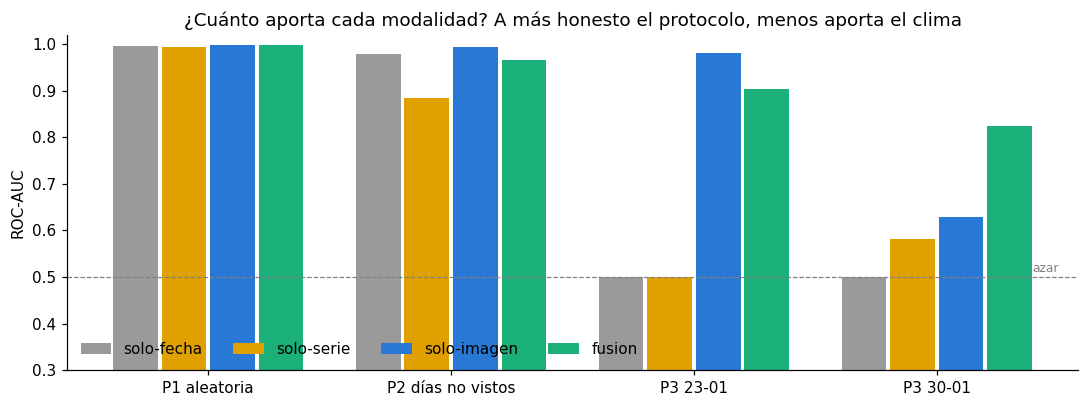

In [27]:
# Celda 25 - Grafica de la ablacion (para el cliente)
fig, ax = plt.subplots(figsize=(10, 3.8))
prot = list(tabla_C.columns); vs = ["solo-fecha", "solo-serie", "solo-imagen", "fusion"]
ancho = 0.2
for i, v in enumerate(vs):
    vals = tabla_C.loc[v, prot].values.astype(float)
    ax.bar(np.arange(len(prot)) + (i - 1.5) * ancho, vals, ancho * 0.92, color=COL_MOD[v], label=v)
ax.axhline(0.5, color="gray", ls="--", lw=0.8); ax.text(len(prot) - 0.5, 0.51, "azar", color="gray", fontsize=8, ha="right")
ax.set_xticks(range(len(prot))); ax.set_xticklabels(prot); ax.set_ylim(0.3, 1.02); ax.set_ylabel("ROC-AUC")
ax.set_title("¿Cuánto aporta cada modalidad? A más honesto el protocolo, menos aporta el clima")
ax.legend(frameon=False, ncol=4, loc="lower left"); plt.tight_layout()
plt.savefig("figuras/f2_ablacion.png", dpi=200, bbox_inches="tight"); plt.show()

In [ ]:
# Celda 25b - De donde sale la "mejora" de la fusion el 30 de enero
for d in DIAS_MIXTOS:
    x = man[man["fecha"] == d]
    print(f"{d:%d-%m-%Y}"); print(pd.crosstab(x["celda"], x["clase"]).to_string(), "\n")
k = (man["fecha"] == DIAS_MIXTOS[1]).values
n_enf = int(y_enf[k].sum()); n_vec = int(((man["celda"] != CELDA_DOM).values & k & (y_enf == 1)).sum())
esperado = n_vec / n_enf + (n_enf - n_vec) / n_enf * 0.5
print(f"Si el clima solo 'reconoce' las {n_vec} fotos de la celda vecina y empata el resto: AUC = {coma(esperado)}")
print(f"AUC observado de solo-serie el 30-01: {coma(tabla_C.loc['solo-serie', 'P3 30-01'])}")

23-01-2023
clase          sana  tardio
celda                      
-9.000/33.750   381      46 

30-01-2023
clase          sana  tardio
celda                      
-9.000/33.125     0       5
-9.000/33.750   210      26 

Si el clima solo 'reconoce' las 5 fotos de la celda vecina y empata el resto: AUC = 0,581
AUC observado de solo-serie el 30-01: 0,581


**El clima "acierta" el 30 de enero por una razón equivocada.** Ese día, 5 fotos tardío traen GPS que las ubica en la celda vecina (-9,0 / 33,125), y ninguna foto sana está en esa celda. Su ventana de clima es distinta, así que la rama de serie las separa por **ubicación**, no por información climática. La cuenta lo confirma: si la serie solo pone arriba esas 5 y empata las demás, el AUC esperado es 5/31 + 26/31 x 0,5 = **0,581**, exactamente el observado. Es un segundo atajo, más fino que el de la fecha: la celda funciona como un "código de lote".

### 4.1 Entonces, ¿para qué sirve el clima? La alerta de dos llaves
La ablación responde una pregunta (si el clima ayuda a decidir si **esta hoja** está enferma). Pero el clima responde otra: **cuándo** hay que salir a revisar. Para el cliente, el sistema útil no es un solo número sino dos señales que se combinan en una decisión:

| | Clima sin riesgo Hutton | Clima con riesgo Hutton (rama B) |
|---|---|---|
| **Foto sana** | seguir con la ronda normal | revisar el lote de nuevo en 2-3 días |
| **Foto con tizón** (rama A) | aislar y tratar el foco | **alerta máxima: aplicar fungicida en todo el lote** |

La gráfica siguiente pone las dos ramas sobre la temporada de las fotos (noviembre 2022 a abril 2023, todo en el periodo de prueba de la rama B).

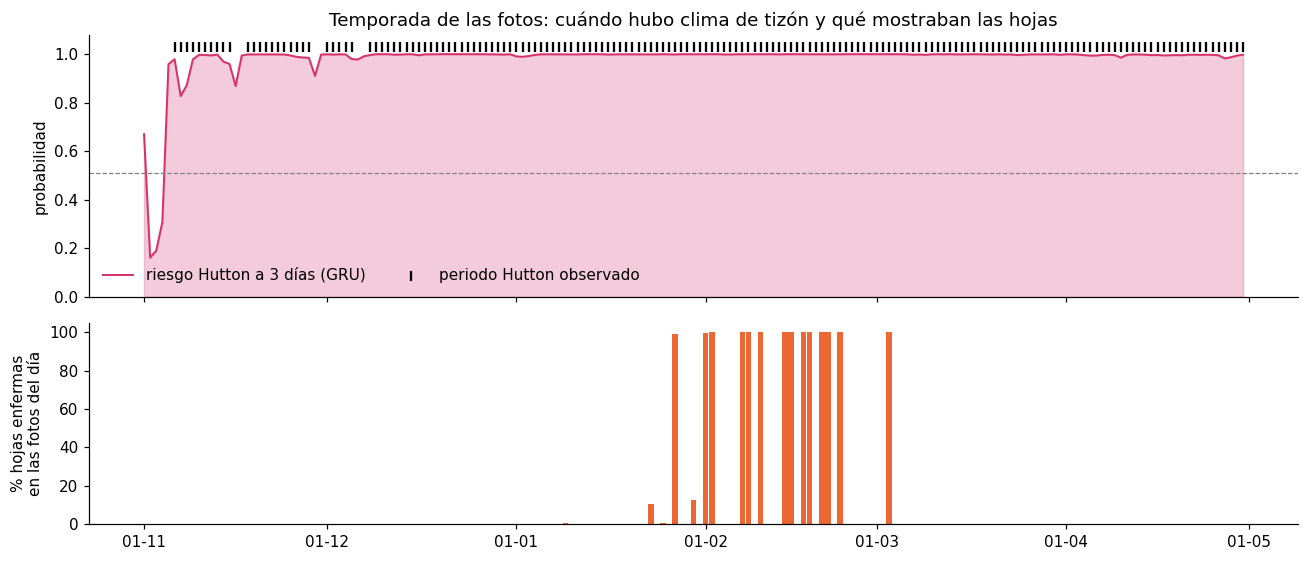

Dias de la temporada con alerta (riesgo >= 0,51): 98% | periodos Hutton observados: 94%


In [28]:
# Celda 26 - Temporada 2022-2023: riesgo climatico de la rama B y estado de las hojas segun las fotos
temp = s.loc["2022-11-01":"2023-04-30"].copy()
fechas_t = [f for f in temp.index if f >= s.index[W - 1]]
Xt = torch.tensor(np.stack([Z[s.index.get_loc(f) - W + 1: s.index.get_loc(f) + 1] for f in fechas_t]))
temp = temp.loc[fechas_t]; temp["riesgo"] = prob_rec(mod_B, Xt)
por_dia = man.groupby("fecha").agg(fotos=("y3", "size"), enfermas=("y3", lambda v: (v > 0).mean()))
fig, ax = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax[0].fill_between(temp.index, temp["riesgo"], color="#d6336c", alpha=0.25)
ax[0].plot(temp.index, temp["riesgo"], color="#d6336c", lw=1.3, label=f"riesgo Hutton a 3 días ({MEJOR_B})")
ev = temp.index[temp["periodo_hutton"] == 1]
ax[0].scatter(ev, np.full(len(ev), 1.03), marker="|", color="black", s=40, label="periodo Hutton observado")
u_b = TAB_B[MEJOR_B]["umbral"]; ax[0].axhline(u_b, color="gray", ls="--", lw=0.8)
ax[0].set_ylim(0, 1.08); ax[0].set_ylabel("probabilidad"); ax[0].legend(frameon=False, loc="lower left", ncol=2)
ax[0].set_title("Temporada de las fotos: cuándo hubo clima de tizón y qué mostraban las hojas")
ax[1].bar(por_dia.index, por_dia["enfermas"] * 100, color="#eb6834", width=0.9)
ax[1].set_ylabel("% hojas enfermas\nen las fotos del día"); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
plt.tight_layout(); plt.savefig("figuras/f2_temporada.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"Dias de la temporada con alerta (riesgo >= {coma(u_b, 2)}): {(temp['riesgo'] >= u_b).mean():.0%} | "
      f"periodos Hutton observados: {temp['periodo_hutton'].mean():.0%}")
RESULTADOS["temporada"] = {"fecha": [f"{d:%Y-%m-%d}" for d in temp.index], "riesgo": temp["riesgo"].round(4).tolist(),
                           "hutton": temp["periodo_hutton"].astype(int).tolist(),
                           "fotos_dia": [{"fecha": f"{d:%Y-%m-%d}", "fotos": int(r.fotos), "pct_enfermas": float(r.enfermas)}
                                         for d, r in por_dia.iterrows()]}

In [29]:
# Celda 27 - Exportar resultados, figuras y pesos (para el informe, el dashboard y el Release)
torch.save(CABEZAS_FE[ARQ_FE].state_dict(), f"pesos/cabeza_fe_{ARQ_FE.lower()}.pth")
Xtr_f, _ = preparar(VARIANTES["fusion"], idx_tr, [idx_va])
RESULTADOS["umbral_B"] = float(TAB_B[MEJOR_B]["umbral"])
with open("resultados_fase2.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
for carpeta in ["pesos", "figuras"]:
    with zipfile.ZipFile(f"{carpeta}_fase2.zip", "w", zipfile.ZIP_DEFLATED) as z:
        for a in sorted(os.listdir(carpeta)): z.write(os.path.join(carpeta, a))
    print(f"{carpeta}_fase2.zip: {os.path.getsize(f'{carpeta}_fase2.zip')/1e6:.1f} MB |", sorted(os.listdir(carpeta)))
try:
    from google.colab import files
    for a in ["resultados_fase2.json", "pesos_fase2.zip", "figuras_fase2.zip"]: files.download(a)
except ImportError:
    print("(fuera de Colab: los archivos quedan en la carpeta actual)")

pesos_fase2.zip: 103.8 MB | ['cabeza_fe_resnet50.pth', 'cnn_mobilenetv3_ft.pth', 'cnn_resnet50_ft.pth', 'gru_hutton.pth', 'rec_gru_w14.pth', 'rec_lstm_w14.pth', 'rec_rnn_w14.pth']
figuras_fase2.zip: 8.8 MB | ['f2_ablacion.png', 'f2_confusion.png', 'f2_curvas_ft.png', 'f2_desvanecimiento.png', 'f2_eda_clases_dias.png', 'f2_errores.png', 'f2_estacionalidad.png', 'f2_gradcam.png', 'f2_muestras.png', 'f2_regresion.png', 'f2_serie.png', 'f2_temporada.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Lectura de la fusión.** Es el resultado más importante del trabajo, y es negativo para el clima:
- **P1 (fotos al azar) no sirve para juzgar la fusión.** Todas las variantes pasan de 0,994, incluida la que solo ve la fecha (0,995) y la que solo ve el clima (0,994). Con fotos del mismo día a ambos lados de la partición, cualquier variable que identifique el día "predice" la enfermedad.
- **P2 (días no vistos) separa señal de atajo.** La imagen sola se sostiene (0,993). El clima solo cae a 0,884, y la fusión (0,965) queda **por debajo de la imagen sola**: el clima le mete ruido. La fecha sola aún da 0,978 porque la campaña fotografió primero lotes sanos y después enfermos, y esa tendencia se extrapola a días nuevos. Es un artefacto de cómo se recolectaron los datos, no agronomía.
- **P3 (dentro de un mismo día) es la prueba ácida.** El 23 de enero el clima es idéntico para todas las fotos: serie y fecha valen 0,5, y la fusión (0,903) vuelve a quedar debajo de la imagen (0,980). El 30 de enero la fusión parece ganar (0,824 frente a 0,629), pero la celda 25b muestra que esa ganancia sale de 5 fotos de la celda vecina, todas tardío.
- **Conclusión para el cliente.** Con estos datos, el clima **no ayuda a decidir si una hoja está enferma**: eso lo resuelve la foto. El clima sirve para otra cosa, que es decidir **cuándo** salir a revisar. En la temporada 2022-2023, la GRU (que nunca vio esos años) marcó riesgo en el 98 % de los días. Después de unos días bajos a comienzos de noviembre, se encendió de forma sostenida el 5 de noviembre, un día antes del primer periodo Hutton observado (6 de noviembre). Por eso proponemos la **alerta de dos llaves** (sección 4.1) y no un único modelo fusionado.

## 5. Autoevaluación contra la rúbrica

| Criterio (peso) | Dónde está la evidencia | Nivel que buscamos |
|---|---|---|
| 1. Rama visual, CNN y transfer learning (20 %) | §2: ficha de ResNet50 vs MobileNetV3 (parámetros, profundidad, latencia), FE vs FT en las dos con la misma partición, matriz de confusión y métricas por clase, prueba en días mixtos, Grad-CAM cualitativo y cuantitativo | Estratégico |
| 2. Rama temporal, LSTM/GRU con RNN de contraste (20 %) | §3: ventana de 14 días justificada con EDA y ACF/PACF, partición cronológica, RNN/LSTM/GRU con 3 semillas, líneas base, regresión con RMSE/MAE/MAPE, dos evidencias del desvanecimiento, decisión GRU vs LSTM en validación | Estratégico |
| 3. Fusión, ablación y alineación legítima (30 %) | §1 y §4: clave (fecha, celda) con co-registro por muestra, fusión tardía de embeddings, ablación de 4 variantes en 3 protocolos, análisis honesto del atajo de la fecha, alerta de dos llaves | Estratégico |
| 4. Uso responsable de IA (15 %) | Anexo A (fuga real reproducida y corregida), Anexo C (bitácora con casos modificados y rechazados) | Estratégico, se defiende en la sustentación |
| 5. Comunicación de resultados (15 %) | Figuras comentadas para el cliente (temporada, ablación, Grad-CAM), informe PDF de 8 páginas con APA, dashboard interactivo (bonus) | Estratégico |

## Anexo A - Auditoría a la IA: tres sospechas de fuga, medidas

**Qué sugirió la IA.** Al armar la fusión, la IA propuso dos cosas que parecían razonables:
1. Evaluar la fusión con la misma partición aleatoria de la rama A (P1) y pasarle el clima crudo de los 14 días.
2. Reutilizar como $z_{img}$ el embedding del **modelo afinado**, "porque es el mejor".

**Por qué desconfiamos.** En la Fase 1 ya vimos que la fecha sola predice la clase (AUC 0,998). Si el clima es igual para todas las fotos de un día, el clima puede funcionar como un código de fecha. Y el modelo afinado vio las etiquetas del 70 % de las fotos, que en la validación por días caen en prueba.

**Cómo se verificó.** La celda siguiente mide las dos cosas: el clima crudo bajo P1, y el AUC del embedding afinado separado según si la foto estuvo o no en el entrenamiento de la rama A. Si hay fuga, las fotos "ya vistas" deben dar un AUC claramente más alto.

In [30]:
# Anexo A - Reproduccion: embedding afinado (con fuga) vs congelado (sin fuga) en P2, y clima crudo en P1
arq_ft = MEJOR_A[0]
with torch.no_grad():
    bb_ft = MODELOS_FT[arq_ft][0].eval(); emb = []
    for xb, _ in cargador(idx_all, tf_eval, 128): emb.append(bb_ft(xb.to(DEVICE)).float().cpu())
Z_ft_full = torch.cat(emb).numpy()
VARIANTES["solo-imagen (FT, con fuga)"] = [("img", Z_ft_full)]
VARIANTES["solo-serie cruda"] = [("cruda", Z_cruda_full)]
oof_ft = np.zeros(len(man))
for k, (tr_all, te) in enumerate(gkf.split(Z_img_full, y_enf, groups=dias)):
    va = tr_all[:: 7]; tr = np.setdiff1d(tr_all, va)
    oof_ft[te] = correr("solo-imagen (FT, con fuga)", tr, va, te)
visto = (man["split"] == "train").values
aud = {"FT, fotos que la rama A ya vio": roc_auc_score(y_enf[visto], oof_ft[visto]),
       "FT, fotos nuevas": roc_auc_score(y_enf[~visto], oof_ft[~visto]),
       "congelado, fotos que la rama A ya vio": roc_auc_score(y_enf[visto], OOF["solo-imagen"][visto]),
       "congelado, fotos nuevas": roc_auc_score(y_enf[~visto], OOF["solo-imagen"][~visto])}
p_cruda = correr("solo-serie cruda", idx_tr, idx_va, idx_te)
aud["clima crudo, P1 aleatoria"] = roc_auc_score(y_enf[idx_te], p_cruda)
for k, v in aud.items(): print(f"{k:42} AUC {coma(v)}")
RESULTADOS["auditoria"] = {k: float(v) for k, v in aud.items()}
with open("resultados_fase2.json", "w", encoding="utf-8") as f:
    json.dump(RESULTADOS, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))

FT, fotos que la rama A ya vio             AUC 0,998
FT, fotos nuevas                           AUC 0,997
congelado, fotos que la rama A ya vio      AUC 0,993
congelado, fotos nuevas                    AUC 0,994
clima crudo, P1 aleatoria                  AUC 0,998


**Veredicto de la auditoría.**
1. **La fuga del clima es real y grande.** Con la partición aleatoria que sugirió la IA, el clima crudo de 14 días "predice" la hoja enferma con AUC 0,998, y el embedding de la GRU con 0,994. En días no vistos baja a 0,884 y dentro de un mismo día a 0,5. Sin el protocolo P2/P3 habríamos reportado que el clima predice el tizón de cada hoja, que es falso. **Corrección:** P2 y P3 son la evaluación principal de la rama C, y P1 queda solo como contraste.
2. **La sospecha sobre el embedding afinado no se confirmó.** Medimos lo que temíamos: con el embedding del modelo afinado, las fotos que la rama A ya había visto dan AUC 0,998 y las nuevas 0,997, una diferencia mínima. La CNN generaliza bien y no memorizó las fotos. Igual mantenemos el backbone congelado en la fusión por principio, y lo reportamos tal cual: una sospecha razonable que los datos desmintieron.
3. **Un tercer atajo que la IA no vio.** Al revisar el 30 de enero apareció el atajo de la celda vecina (celda 25b): la "mejora" de la fusión salía de la ubicación de 5 fotos. Lo encontramos al mirar los datos foto por foto, no con una métrica.

## Anexo B - Propuesta de Datos v2
Documento completo en `propuesta/Propuesta de Datos Fase 2.pdf`. Cambios frente a la v1: la imagen entra cruda (muestra de 6.695 fotos sin EXIF, publicada como Release), la serie pasa de 10 filas de ejemplo a 25 años de clima horario en dos celdas, y la clave de alineación se vuelve (fecha, celda) con co-registro por foto.

## Anexo C - Bitácora de IA (Fase 2)
Cada entrada remite a la celda o sección que afecta. **Revisar, completar con los casos propios y firmar antes de entregar.**

| Fecha | Herramienta | Sugerencia de la IA | Decisión | Verificación y evidencia | Afecta |
|---|---|---|---|---|---|
| 2026-11-07 | Claude | Subir las 6.695 fotos al repositorio con "Add file" | Modificada | GitHub corta en 25 MB por archivo; se publicó como Release (`datos-fase2`) | Celda 1 |
| 2026-11-07 | Claude | Guardar coordenadas GPS exactas de cada foto en el manifiesto | Rechazada | Basta la celda NASA POWER (0,5° x 0,625°); no se guardan ni se publican coordenadas | `preparar_imagenes_fase2.py`, celda 4 |
| 2026-11-07 | Claude | Script de clima con `replace(-999, pd.NA)` | Modificada | La prueba local falló al convertir a float; se cambió por `mask(x <= -998)` | `descargar_clima_fase2.py` |
| 2026-11-07 | Claude | Usar el clima diario (no horario) para el criterio de Hutton | Rechazada | Hutton cuenta horas con HR >= 90 %; con la media diaria no se puede calcular | Celda 3 |
| 2026-11-07 | Claude | Evaluar la rama B solo en el año completo | Modificada | El EDA mostró Hutton en 97-100 % de los días de dic-abr; se agregó la evaluación en meses de transición | Celda 18b |
| 2026-11-07 | Claude | Elegir el mejor modelo de la rama A por F1 en prueba | Rechazada | Se elige en validación; la prueba se mira solo al final | Celda 9 |
| 2026-11-07 | Claude | Evaluar la fusión solo con partición aleatoria (P1) | Modificada | Clima crudo AUC 0,998 en P1, 0,5 dentro del día; se agregaron P2 y P3 | Celda 24, Anexo A |
| 2026-11-07 | Claude | Usar el embedding del modelo afinado en la fusión | Modificada | Se midió la fuga: 0,998 (vistas) frente a 0,997 (nuevas), mínima; se mantiene el congelado por principio | Celda 23, Anexo A |
| 2026-11-07 | Equipo | (no lo propuso la IA) Revisar foto por foto el 30 de enero | Propia | 18 de 31 fotos "tardío" sin lesión visible; 5 de la celda vecina explican la "mejora" de la fusión | Celdas 12b y 25b |
| 2026-11-07 | Claude | Estructura de este cuaderno (ramas A, B y C) | Modificada | Se ejecutó completo en Colab (T4); cifras revisadas contra `resultados_fase2.json` | Todo |

| Integrante | Firma | Fecha |
|---|---|---|
| Juan Guillermo Montaño Junca | | |
| Jair Andrés Valderrama Cano | | |

## Anexo D - Informe técnico
PDF aparte en `Informe/Informe Fase 2 Centinela Papa.pdf` (máximo 8 páginas): metodología, resultados de las tres ramas, ablación, limitaciones y recomendaciones para el cliente, con citación APA 7. Cada cifra sale de `resultados_fase2.json`, que genera este cuaderno.

**Referencias principales:** He et al. (2016); Howard et al. (2019); Selvaraju et al. (2017); Hochreiter y Schmidhuber (1997); Cho et al. (2014); Baltrušaitis et al. (2019); Laizer y Mduma (2025); NASA POWER (2025); Met Office / AHDB, criterio de Hutton (2017).